# TERRA Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 26.01.2025
- Date of Last Modification: 30.05.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the terra-reproducibility conda environment ```../../envs/terra-reproducibility.yaml``` or the rapids_singlecell_terra conda environment ```../../envs/rsc_rapids_25.10_terra.yaml``` (GPU-accelerated clustering).

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import warnings

import anndata as ad
try:
    import squidpy as sq
    print("Did not load rapids singlecell...")
except:
    import dask
    dask.config.set({"dataframe.query-planning": True}) # this is required to make rapids_singlecell work
    import dask.dataframe.dask_expr
    import rapids_singlecell as rsc
    print("Did not load squidpy...")
import pandas as pd
import scanpy as sc
import scib_metrics
from app.inference import harmonize_tokenize_embed_pipeline
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Did not load squidpy...


2026-06-05 22:01:36 | [INFO] JAX version 0.8.1 available.
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/spatialdata/_core/query/relational_query.py:530: FutureWarning: functools.partial will be a method descriptor in future Python versions; wrap it in enum.member() if you want to preserve the old behavior
  left = partial(_left_join_spatialelement_table)
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/spatialdata/_core/query/relational_query.py:531: FutureWarning: functools.partial will be a method descriptor in future Pyt

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/terra-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
#model_timestamp = '01112025_081731_614'
#model_timestamp = '11012026_190057_836'
#model_timestamp = '06022026_161017_190'
model_timestamp = '03112025_004451_930'
#model_timestamp = '29102025_142759_837'
model_timestamp = '11112025_172307_218'
model_folder_path = f'/nfs/team361/sb75/terra-reproducibility/artifacts/models/{model_timestamp}'
cache_directory_path = f'/nfs/team361/sb75/terra-reproducibility/artifacts/cache'

### 1.3 Define Config

In [5]:
min_cells_per_gene = 0
min_cells_per_niche = 100
latent_neighborhood_cluster_key = 'predicted_niche'
latent_cell_cluster_key = 'predicted_cell_type'

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/TERRA', exist_ok=True)

## 2. Zero-shot Niche Identification

### 2.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

#### 2.1.1 Load Data

In [11]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
niche_key = 'niche'
sample_key = 'batch'
batch_key = 'batch_new'
spot_sizes = [80 * 0.18] * len(batches)

In [12]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

/tmp/ipykernel_2885287/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2885287/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2885287/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2885287/2347038608.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2885287/2347038608.py:13: ImplicitMod

#### 2.1.2 Retrieve Embeddings

In [307]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 0 genes.
Before cell filtering: 533961 cells.
After cell filtering: 533961 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 946 genes.
After gene filtering: 946 genes (removed 0 genes).
Start processing sample: 59batch4...
Harmonizing sample 59batch4...
STEP 1: DATA VALIDATION...
Checking that adata.X contai

/nfs/team361/sb75/terra/src/app/inference/harmonize.py:124: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names
2026-06-04 17:38:16 | [INFO] Loading token dictionary from /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/token_dictionary.pkl.


Before cell filtering: 83723 cells.
After cell filtering: 83723 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 946 genes.
After gene filtering: 946 genes (removed 0 genes).
Harmonized sample 59batch4.
Tokenizing sample 59batch4...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/terra/src/terra/tokenizers/cell_tokenizers.py:678: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts (sparse version).
Retrieving tokens for neighborhood cells.


2026-06-04 17:39:02 | [INFO] Creating Hugging Face dataset...
2026-06-04 17:39:02 | [INFO] Using generator for dataset creation.
2026-06-04 17:39:18 | [INFO] Formatting gene tokens...
Map (num_proc=4):   0%|  | 0/83723 [00:00<?, ? examples/s]Exception ignored in: <_io.BytesIO object at 0x14c2241a98a0>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Map (num_proc=4): 100%|▉| 83689/83723 [01:17<00:00, 684.81Exception ignored in: <_io.BytesIO object at 0x14c232df0b80>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/pyarrow/util.py", line 138, in _stringify_path
    def _stringify_path(path):
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x14c2241a8590>

... (43 outputs left out)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
2026-06-04 17:54:31 | [INFO] Dataloader and -sampler created.
2026-06-04 17:54:33 | [INFO] Loaded pretrained target encoder from epoch 8 with msg: <All keys matched successfully>.
2026-06-04 17:54:33 | [INFO] Finished loading checkpoint with read path: /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/terra/src/app/inference/embed.py:257: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
4172it [1:22:08,  1.18s/it]


Embedded tokenized data.


In [308]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

... storing 'batch' as categorical
... storing 'batch_new' as categorical


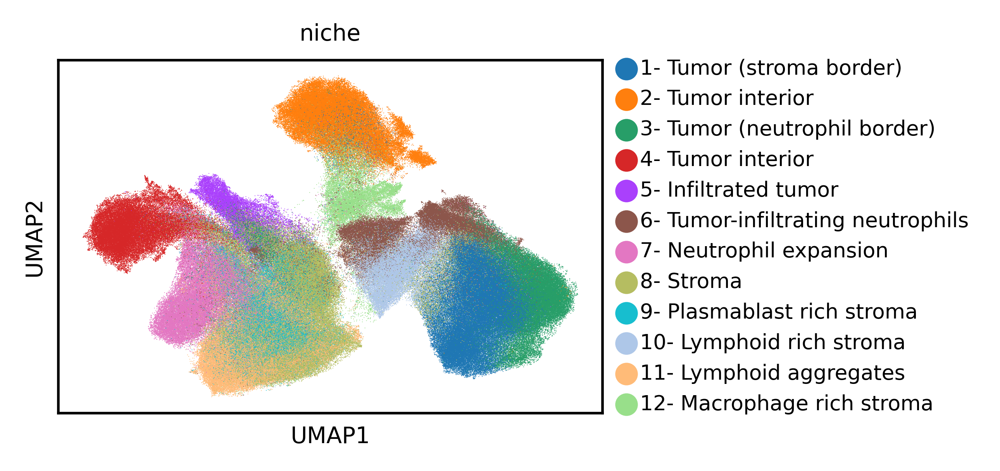

In [309]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [310]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [137]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 0 genes.
Before cell filtering: 533961 cells.
After cell filtering: 533961 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 946 genes.
After gene filtering: 946 genes (removed 0 genes).
Start processing sample: 59batch4...
Harmonizing sample 59batch4...
STEP 1: DATA VALIDATION...
Checking that adata.X contai

/nfs/team361/sb75/terra/src/app/inference/harmonize.py:124: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names
2026-06-04 01:48:41 | [INFO] Loading token dictionary from /nfs/team361/sb75/terra-reproducibility/artifacts/models/29102025_142759_837/token_dictionary.pkl.


Before cell filtering: 83723 cells.
After cell filtering: 83723 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 946 genes.
After gene filtering: 946 genes (removed 0 genes).
Harmonized sample 59batch4.
Tokenizing sample 59batch4...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts (sparse version).


/nfs/team361/sb75/terra/src/terra/tokenizers/cell_tokenizers.py:678: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Retrieving tokens for neighborhood cells.


2026-06-04 01:49:27 | [INFO] Creating Hugging Face dataset...
2026-06-04 01:49:27 | [INFO] Using generator for dataset creation.
2026-06-04 01:49:46 | [INFO] Formatting gene tokens...
Map (num_proc=4):   0%|                                   | 0/83723 [00:00<?, ? examples/s]Exception ignored in: <_io.BytesIO object at 0x14c220c23510>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x14c220c23d80>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Map (num_proc=4):   0%|                         | 8/83723 [00:01<4:52:16,  4.77 examples/s]

... (41 outputs left out)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
2026-06-04 02:05:24 | [INFO] Dataloader and -sampler created.
2026-06-04 02:05:24 | [INFO] Loaded pretrained target encoder from epoch 4 with msg: <All keys matched successfully>.
2026-06-04 02:05:24 | [INFO] Finished loading checkpoint with read path: /nfs/team361/sb75/terra-reproducibility/artifacts/models/29102025_142759_837/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/terra/src/app/inference/embed.py:257: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
4172it [1:22:39,  1.19s/it]


Embedded tokenized data.


In [138]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

... storing 'batch_new' as categorical


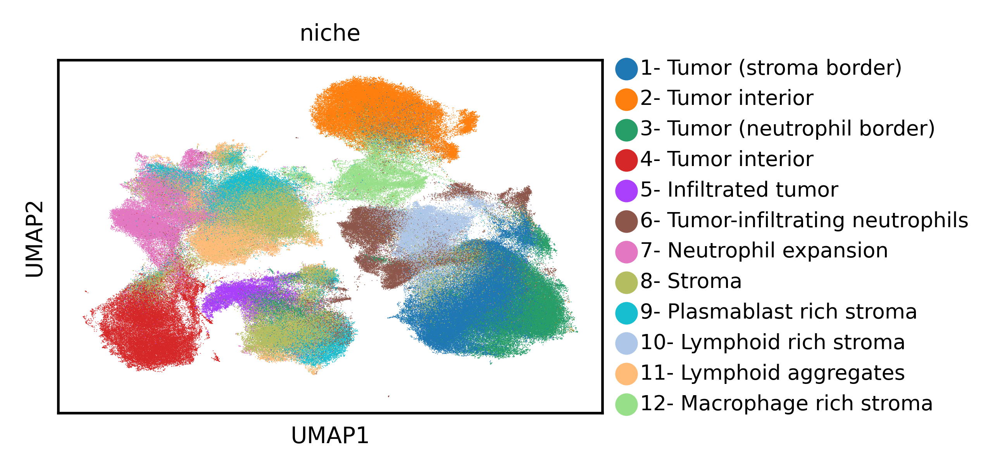

In [139]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [140]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [20]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [21]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 0.32
latent_leiden_resolution = 0.45

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [22]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

predicted_niche
0     92990
1     89144
2     64581
3     59662
4     49509
5     45369
6     37131
7     33004
8     31399
9     28908
10     2087
11      177
Name: count, dtype: int64

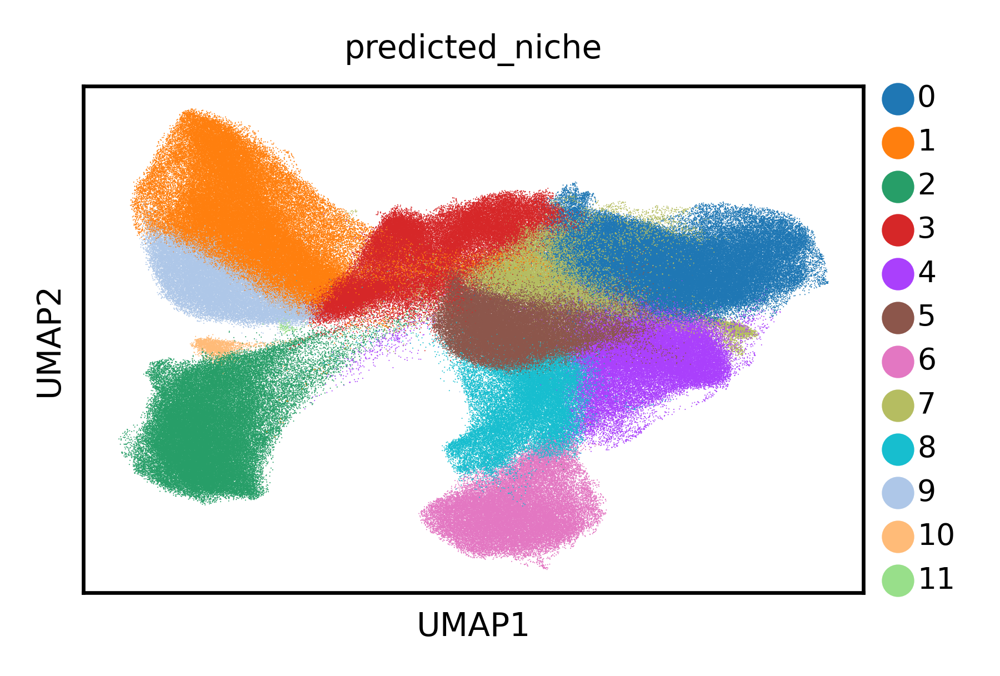

In [23]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [26]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [27]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

['2', '3', '1', '10', '9', '7', '8', '4', '0', '5', '11', '6']
predicted_niche
0     92990
1     89144
2     64581
3     59662
4     49509
5     45369
6     37131
7     33004
8     31399
9     28908
10     2087
11      177
Name: count, dtype: int64
Optimal Mappings:
1- Tumor (stroma border) -> 1 (Overlap: 72559)
2- Tumor interior -> 2 (Overlap: 57208)
3- Tumor (neutrophil border) -> 9 (Overlap: 23925)
4- Tumor interior -> 6 (Overlap: 35856)
5- Infiltrated tumor -> 8 (Overlap: 12811)
6- Tumor-infiltrating neutrophils -> 7 (Overlap: 14692)
7- Neutrophil expansion -> 4 (Overlap: 35387)
8- Stroma -> 5 (Overlap: 27733)
9- Plasmablast rich stroma -> 11 (Overlap: 0)
10- Lymphoid rich stroma -> 3 (Overlap: 19853)
11- Lymphoid aggregates -> 0 (Overlap: 30344)
12- Macrophage rich stroma -> 10 (Overlap: 1)

Total Maximum Overlap: 330369


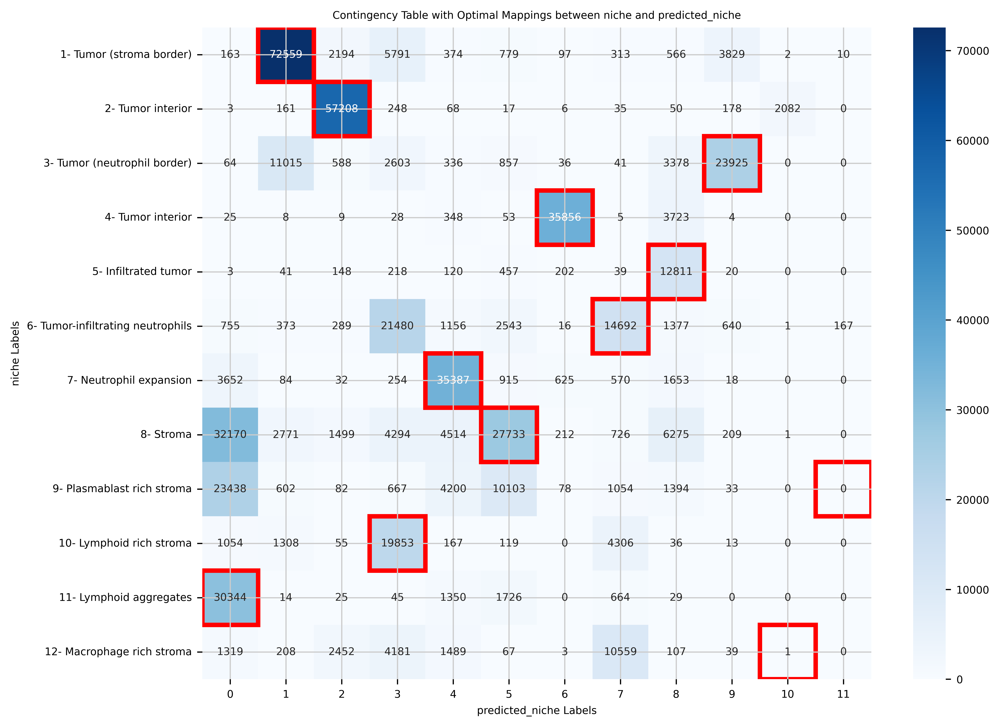

In [29]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [30]:
inferred_niches_ordered = [
    '1',
    '2',
    '9',
    '6',
    '8',
    '7',
    '4',
    '5',
    '11',
    '3',
    '0',
    '10',
    '11']

/tmp/ipykernel_2885287/2508450644.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


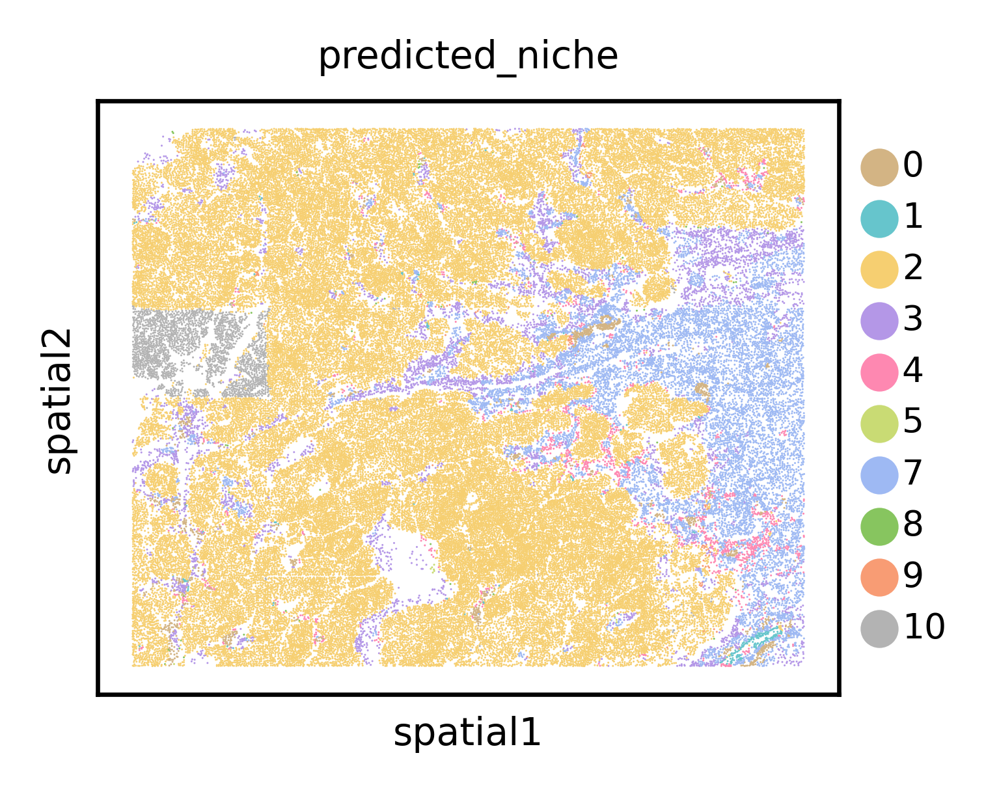

/tmp/ipykernel_2885287/2508450644.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


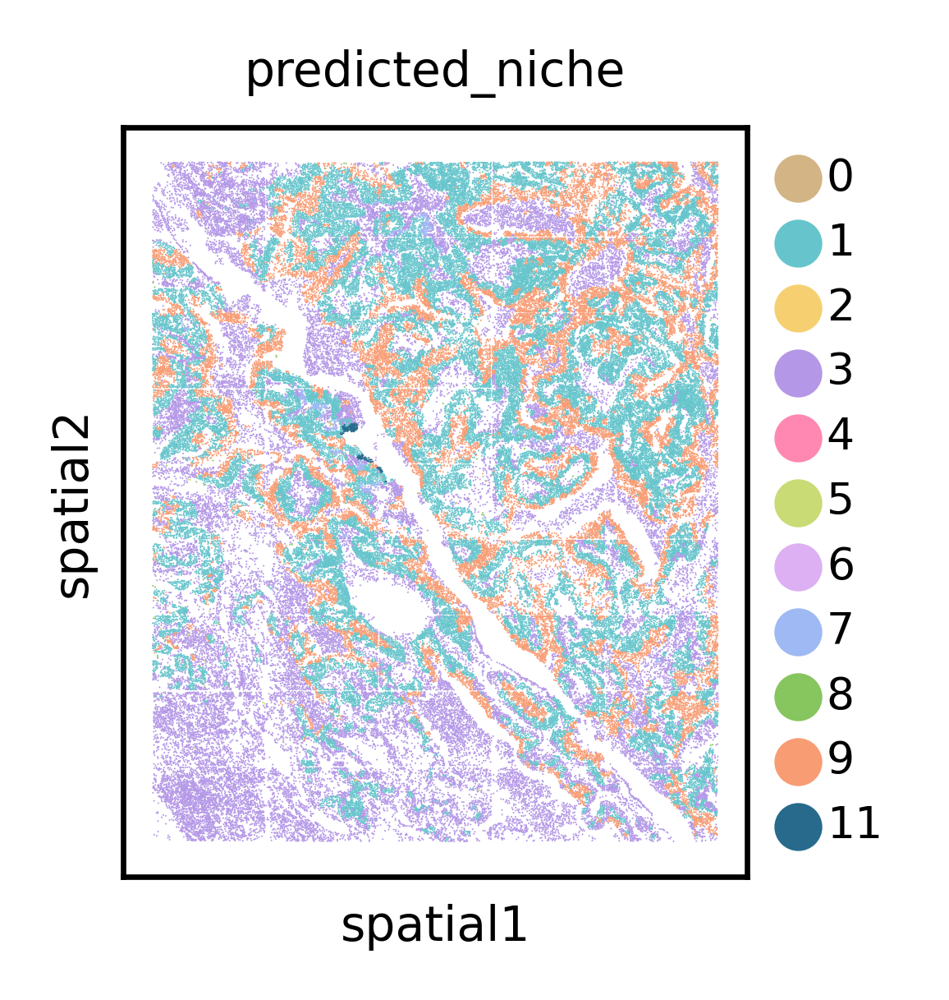

/tmp/ipykernel_2885287/2508450644.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


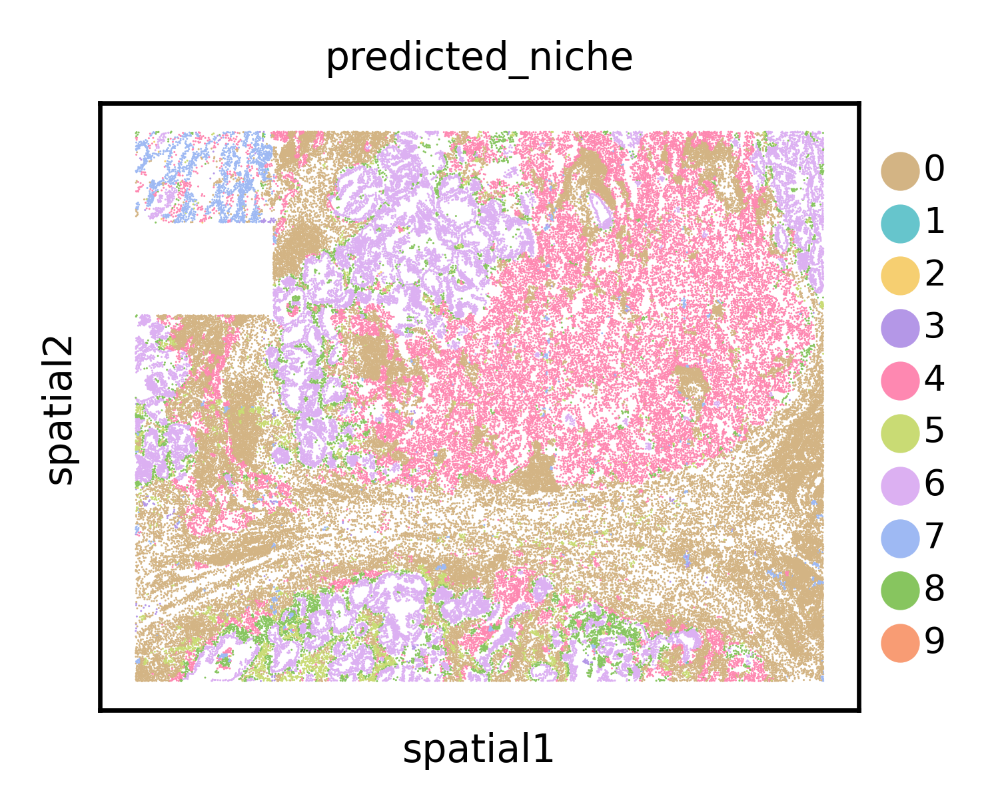

/tmp/ipykernel_2885287/2508450644.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


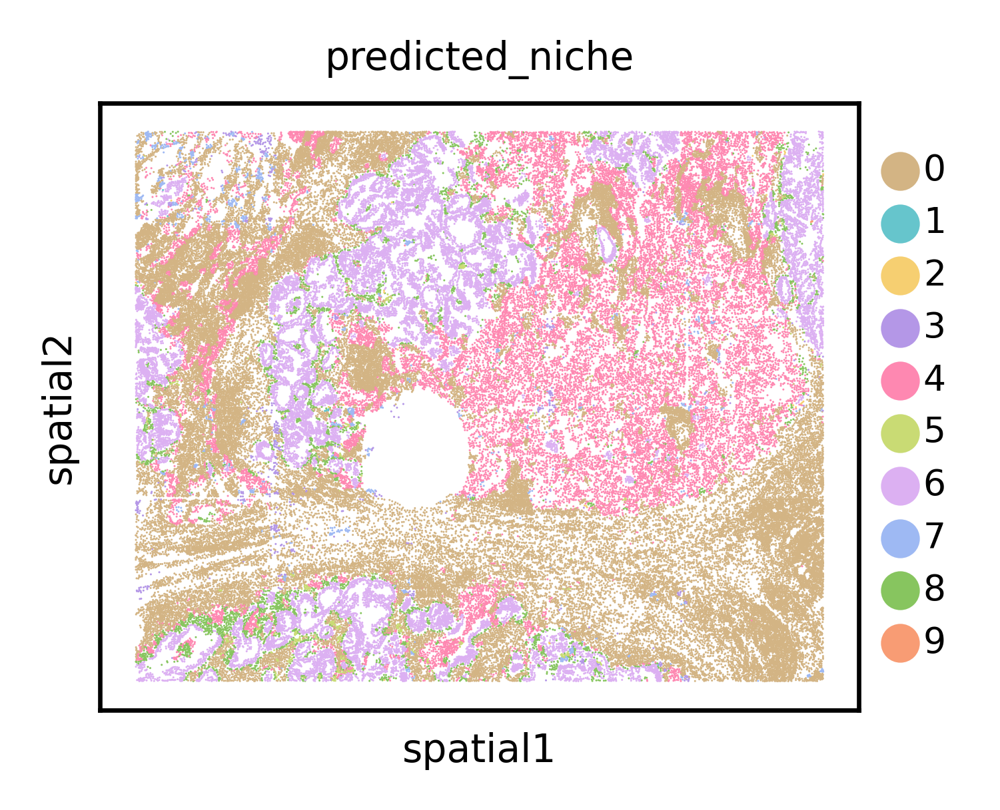

/tmp/ipykernel_2885287/2508450644.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


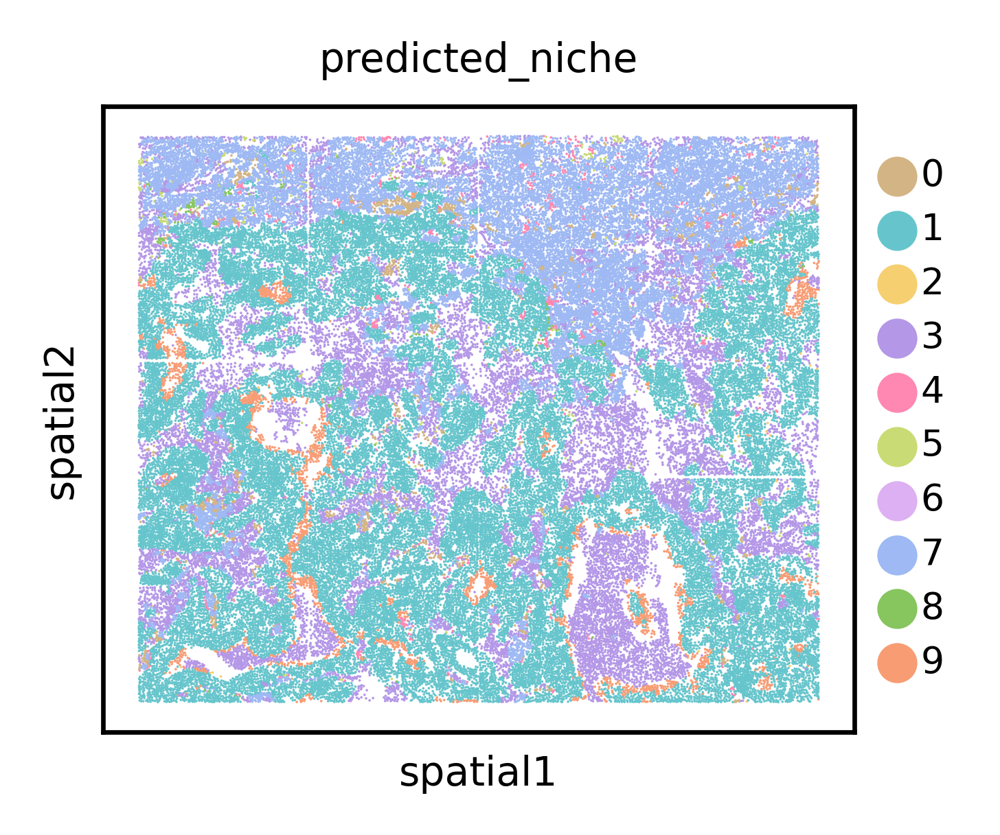

/tmp/ipykernel_2885287/2508450644.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


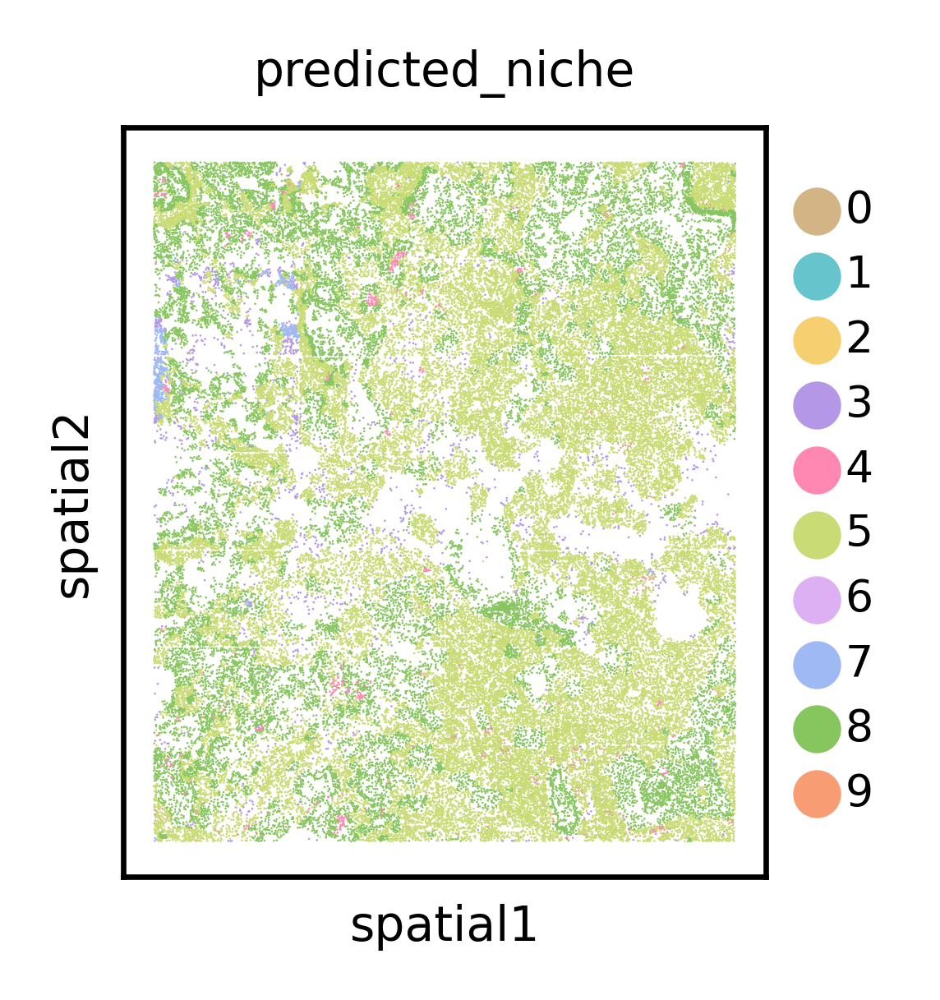

In [31]:
# Plot TERRA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_niches_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [32]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5787450901873582.
ARI scores: 0.4838787869633426.


#### 2.1.4 Quantitative Performance

In [33]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.5787450901873582, 0.5732325504457423, 0.5797854703974106, 0.5803385939815305, 0.580899925441851, 0.5791011249095078, 0.5786685447328945, 0.5818581702134958, 0.5808637891315449].
ARI scores: [0.4838787869633426, 0.46990159373996876, 0.48477623584735724, 0.4850868360852309, 0.4899008139848094, 0.4818613435111902, 0.48267402730945924, 0.4851000920945192, 0.4925505509147582].


### 2.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Define dataset params
dataset_name = 'chr78-11b_1p'
batches = ['CM007',
           'CM008',
           'CM009',
           'CM011',
           'CM013',
           'CM015',
           'CM016',
           'CM017',
           'CM018',
           'CM019',
           'CM020']
niche_key = 'broad_anatomy'
sample_key = 'sample'
batch_key = 'batch'
spot_sizes = [240 * 0.093] * len(batches)

#### 2.2.1 Load Data

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.093 # conversion rate from Valentina

In [ ]:
# Combine regions
adata.obs[niche_key] = adata.obs[niche_key].apply(lambda x: x.replace('Urogenital Sinus', 'UrogenitalSinus'))

In [ ]:
print(adata.obs[niche_key].value_counts())

#### 2.2.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.2.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 19)
latent_leiden_resolution = 0.4

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '11',
    '13',
    '6',
    '9',
    '7',
    '0',
    '2',
    '5',
    '15',
    '17',
    '8',
    '10',
    '18',
    '14',
    '3',
    '16',
    '4',
    '12',
    '1']

In [ ]:
# Plot TERRA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_niches_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.2.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.3 xhs49-1b_1p (Xenium Human Melanoma)

In [ ]:
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
batch_key = 'batch'
spot_size = 20

#### 2.3.1 Load Data

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Xenium_Prime_Human_Skin_FFPE_outs.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs['niche_name'].isna()]

In [ ]:
adata.obs[niche_key].value_counts()

#### 2.3.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=None,
    batch_key='batch',
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 8)
latent_leiden_resolution = 0.3

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '6',
    '4',
    '2',
    '7',
    '0',
    '5',
    '1',
    '3']

In [ ]:
# Plot TERRA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_terra_niches_{model_timestamp}.svg'
sc.pl.spatial(adata,
              color=latent_neighborhood_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

#### 2.4.1 Load Data

In [311]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
niche_key = 'niche_type'
sample_key = 'sample'
batch_key = 'batch'
spot_sizes = [20] * len(batches)

In [312]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial']

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_2331359/767950235.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_2331359/767950235.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/767950235.py:13

#### 2.4.2 Retrieve Embeddings

In [313]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 4948.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 0 genes.
Before cell filtering: 53655 cells.
After cell filtering: 53655 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 4948 genes.
After gene filtering: 4948 genes (removed 0 genes).
Start processing sample: BK30_Lesional Baseline...
Harmonizing sample BK30_Lesional Baseline...
STEP 1: DATA VALIDATION...

/nfs/team361/sb75/terra/src/app/inference/harmonize.py:124: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names
2026-06-04 19:24:01 | [INFO] Loading token dictionary from /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/token_dictionary.pkl.


STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 0 genes.
Before cell filtering: 18439 cells.
After cell filtering: 18439 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 4948 genes.
After gene filtering: 4948 genes (removed 0 genes).
Harmonized sample BK30_Lesional Baseline.
Tokenizing sample BK30_Lesional Baseline...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...


/nfs/team361/sb75/terra/src/terra/tokenizers/cell_tokenizers.py:678: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts (sparse version).
Retrieving tokens for neighborhood cells.


2026-06-04 19:24:17 | [INFO] Creating Hugging Face dataset...
2026-06-04 19:24:17 | [INFO] Using generator for dataset creation.
2026-06-04 19:24:22 | [INFO] Formatting gene tokens...
Map (num_proc=4):   0%|                                          | 0/18439 [00:00<?, ? examples/s]Exception ignored in: <_io.BytesIO object at 0x14c1daa6e430>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x14c1daa6d9e0>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Map (num_proc=4): 100%|████████████████████████████▉| 18429/18439 [00:25<00:00, 237.

... (17 outputs left out)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
2026-06-04 19:26:50 | [INFO] Dataloader and -sampler created.
2026-06-04 19:26:50 | [INFO] Loaded pretrained target encoder from epoch 8 with msg: <All keys matched successfully>.
2026-06-04 19:26:50 | [INFO] Finished loading checkpoint with read path: /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/terra/src/app/inference/embed.py:257: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
420it [08:22,  1.20s/it]

Embedded tokenized data.


In [314]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

... storing 'batch' as categorical


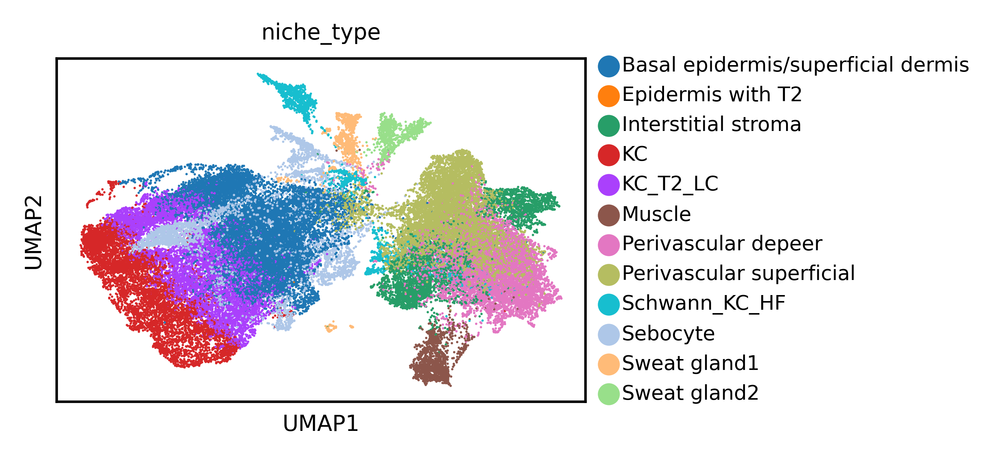

In [315]:
# Visualize UMAP
sc.pl.umap(adata, color=niche_key)

In [316]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 11)
latent_leiden_resolution = 0.21

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_neighborhood_cluster_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_neighborhood_cluster_key].unique().tolist())
print(adata.obs[latent_neighborhood_cluster_key].value_counts())
max_overlap_plot(adata.obs, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '1',
    '9',
    '6',
    '2',
    '4',
    '7',
    '12',
    '0',
    '8',
    '3',
    '10',
    '5',
    '11']

In [ ]:
# Plot TERRA niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_niches_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

## 3. Zero-shot Cell Type Identification

### 3.1 xhs1000-39b_1p (Xenium Human Skin - Eczema)

#### 3.1.1 Load Data

In [420]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
cell_type_key = 'new_annotation' # 'annotation_new7'
sample_key = 'sample'
batch_key = 'batch'
spot_sizes = [20] * len(batches)

In [421]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/3458664098.py

In [422]:
print(adata.obs[cell_type_key].value_counts())

new_annotation
KC1                               9861
KC4                               8301
F2: Universal                     6307
KC3                               4896
T                                 4430
KCinflamm                         3020
Sebocyte_GATA6hi_innersebocyte    2948
VE3                               2692
cDC2                              2601
Pericyte                          1937
Mac                               1590
Muscle                            1241
KC_melanocyte                     1019
Sweat gland channel outer          651
Schwann                            642
Sweat gland                        587
LE                                 347
F5: RAMP1                          328
Mast cell                          200
Pre-adipocyte PPARG+ANGPTL8         52
Plasma cell                          5
Name: count, dtype: int64


#### 3.1.2 Load Embeddings

In [423]:
# Load embeddings from 2.4
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [424]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

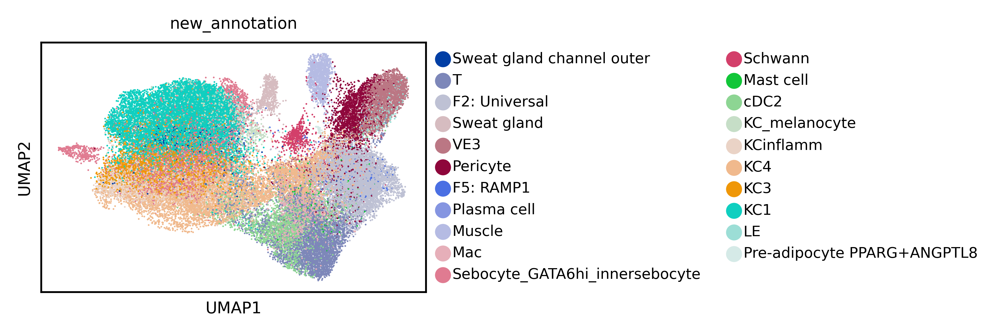

In [425]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [426]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [448]:
# Save updated AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [449]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 19)
# latent_leiden_resolution = 0.8
latent_leiden_resolution = 1.108

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [450]:
adata.obs[latent_cell_cluster_key].value_counts()

predicted_cell_type
0     6953
1     4693
2     4499
3     4206
4     3992
5     3849
6     3662
7     3547
8     3378
9     3109
10    3094
11    2711
12    1406
13    1335
14    1291
15     560
16     559
17     450
18     361
Name: count, dtype: int64

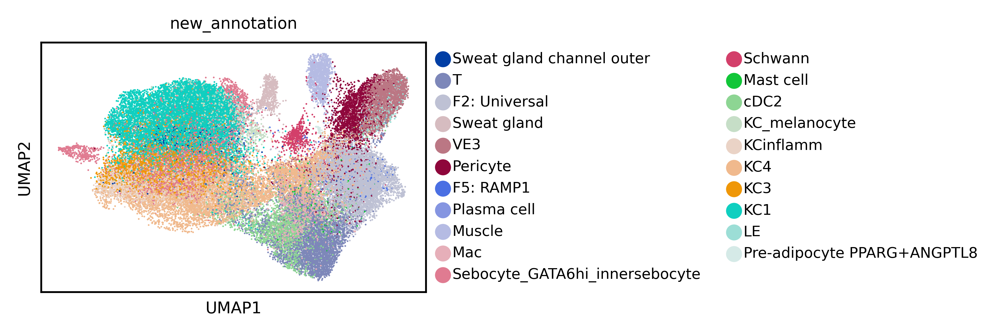

In [451]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [452]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [453]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

['8', '12', '9', '1', '10', '4', '3', '7', '16', '5', '13', '14', '0', '6', '2', '11', '18', '17', '15']
predicted_cell_type
0     6953
1     4693
2     4499
3     4206
4     3992
5     3849
6     3662
7     3547
8     3378
9     3109
10    3094
11    2711
12    1406
13    1335
14    1291
15     560
16     559
17     450
18     361
Name: count, dtype: int64
Optimal Mappings:
Sweat gland channel outer -> 17 (Overlap: 430)
T -> 9 (Overlap: 2664)
F2: Universal -> 7 (Overlap: 2882)
Sweat gland -> 15 (Overlap: 551)
VE3 -> 1 (Overlap: 2616)
Pericyte -> 12 (Overlap: 36)
F5: RAMP1 -> 5 (Overlap: 163)
Plasma cell -> 6 (Overlap: 0)
Muscle -> 14 (Overlap: 1214)
Mac -> 8 (Overlap: 1159)
Sebocyte_GATA6hi_innersebocyte -> 4 (Overlap: 928)
Schwann -> 16 (Overlap: 473)
cDC2 -> 10 (Overlap: 1571)
KC_melanocyte -> 13 (Overlap: 67)
KCinflamm -> 2 (Overlap: 1544)
KC4 -> 11 (Overlap: 2469)
KC3 -> 0 (Overlap: 2634)
KC1 -> 3 (Overlap: 3444)
Pre-adipocyte PPARG+ANGPTL8 -> 18 (Overlap: 40)

Total Maximum Overl

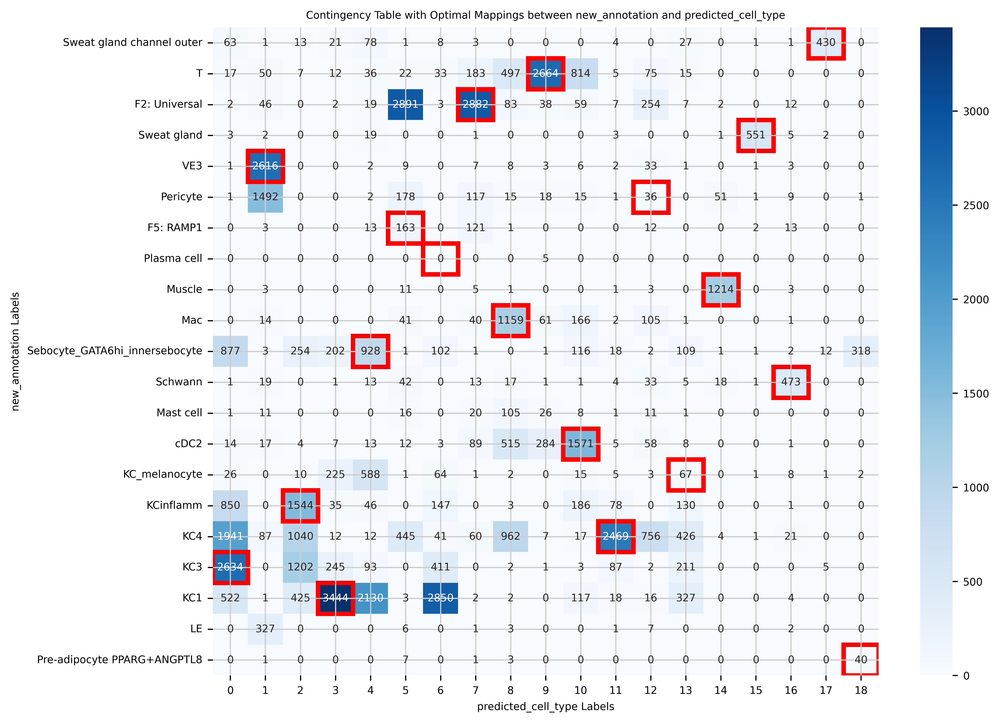

In [454]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [455]:
inferred_cell_types_ordered = [
    '17',
    '9',
    '7',
    '15',
    '1',
    '12',
    '5',
    '6',
    '14',
    '8',
    '4',
    '16',
    '10',
    '13',
    '2',
    '11',
    '0',
    '3',
    '18']

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


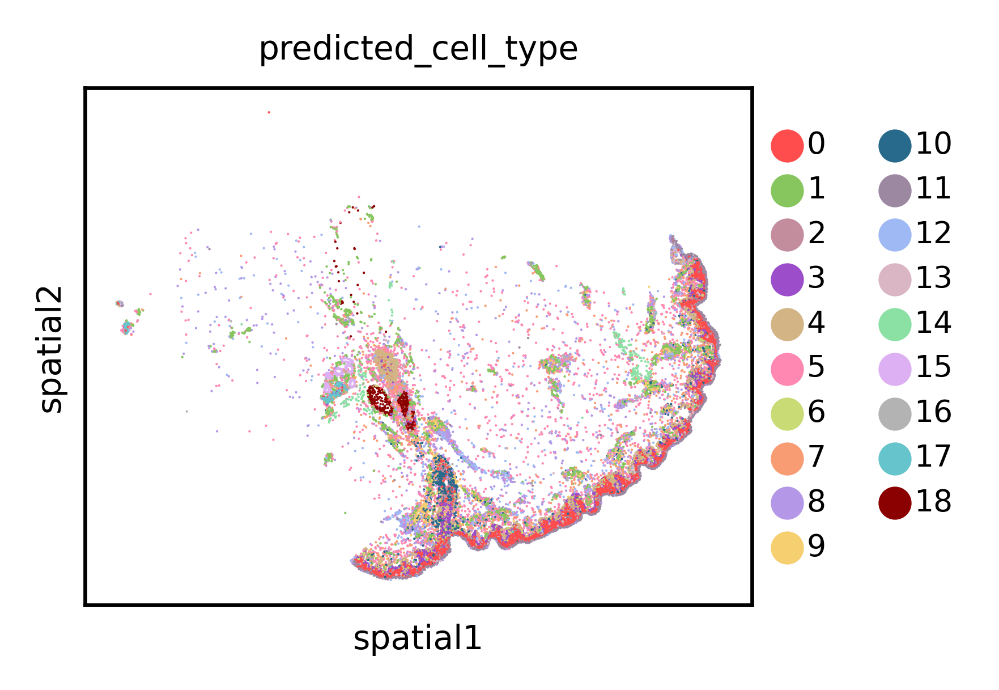

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


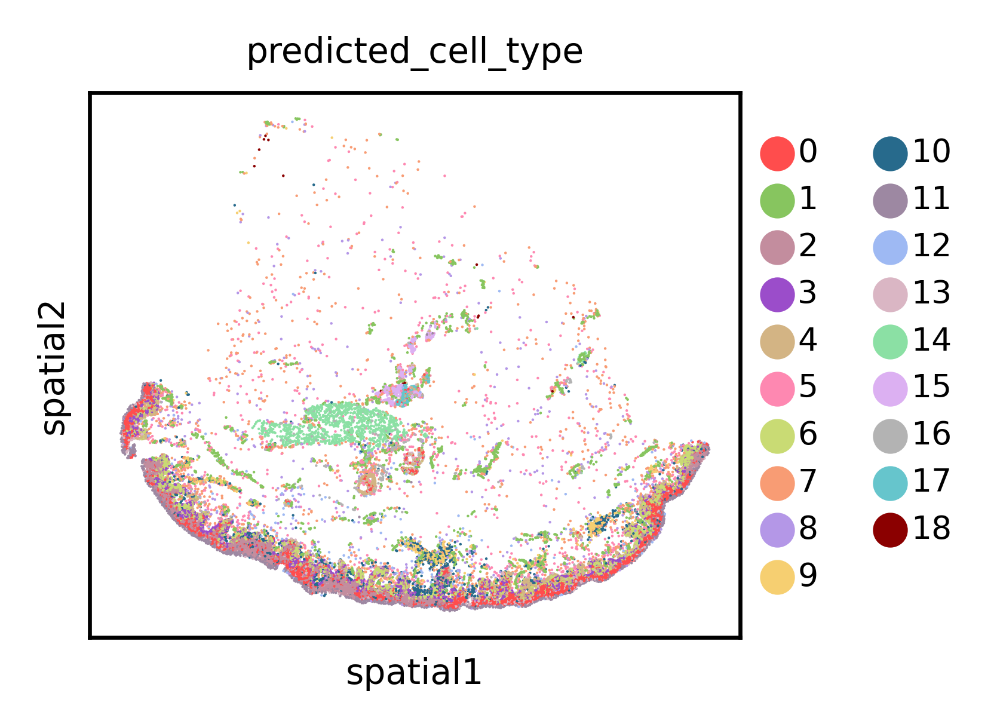

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


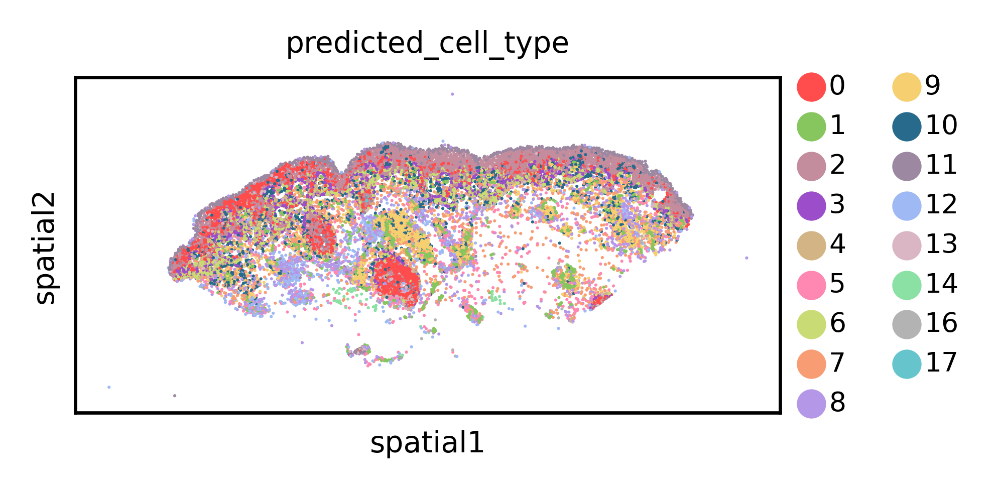

In [456]:
# Plot TERRA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [457]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5367369103142616.
ARI scores: 0.31100112746729663.


#### 3.1.4 Quantitative Performance

In [458]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.5367369103142616, 0.5419627094047691, 0.5426410025808514, 0.5294092260380929, 0.5477784273244231, 0.5453073248550657, 0.5380225225603267, 0.5369621172055064, 0.5355290171898207].
ARI scores: [0.31100112746729663, 0.3471300231790898, 0.35158449134551617, 0.29824976349060195, 0.35972313960115826, 0.35863554832389544, 0.3146848343648644, 0.31250909671423627, 0.311335205839685].


### 3.2 chl59-8b_1p (NanoString CosMx Human NSCLC)

#### 3.2.1 Load Data

In [332]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
cell_type_key = 'cell_type'
sample_key = 'batch'
batch_key = 'batch_new'
spot_sizes = [80 * 0.18] * len(batches)

In [333]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

/tmp/ipykernel_2331359/1245272384.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/1245272384.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/1245272384.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/1245272384.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/1245272384.py:13: Imp

In [334]:
adata.obs[cell_type_key].value_counts()

cell_type
tumor          245918
fibroblast      59082
neutrophil      49628
myeloid         48953
NK/T cell       38465
plasmablast     26574
endothelial     24999
epithelial      17419
B-cell          16475
mast             6448
Name: count, dtype: int64

#### 3.2.2 Load Embeddings

In [335]:
# Load embeddings from 2.1
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [336]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

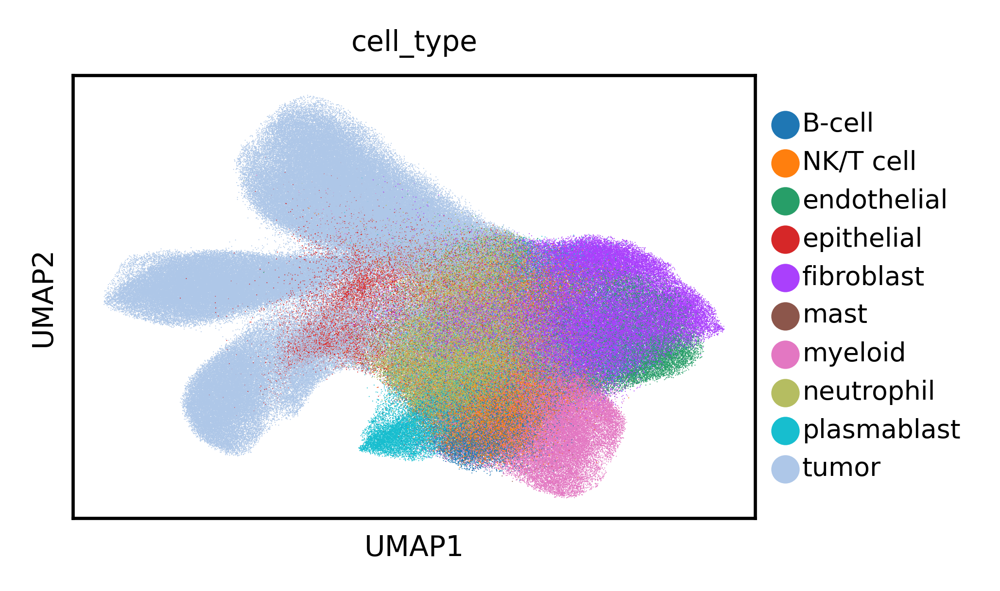

In [337]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [338]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [346]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.2.3 Highlight Run (Matching Ground Truth Number of Niches)

In [347]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 10)
latent_leiden_resolution = 0.57

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [348]:
adata.obs[latent_cell_cluster_key].value_counts()

predicted_cell_type
0    91798
1    88812
2    75168
3    62571
4    60003
5    59712
6    34212
7    31629
8    22579
9     7477
Name: count, dtype: int64

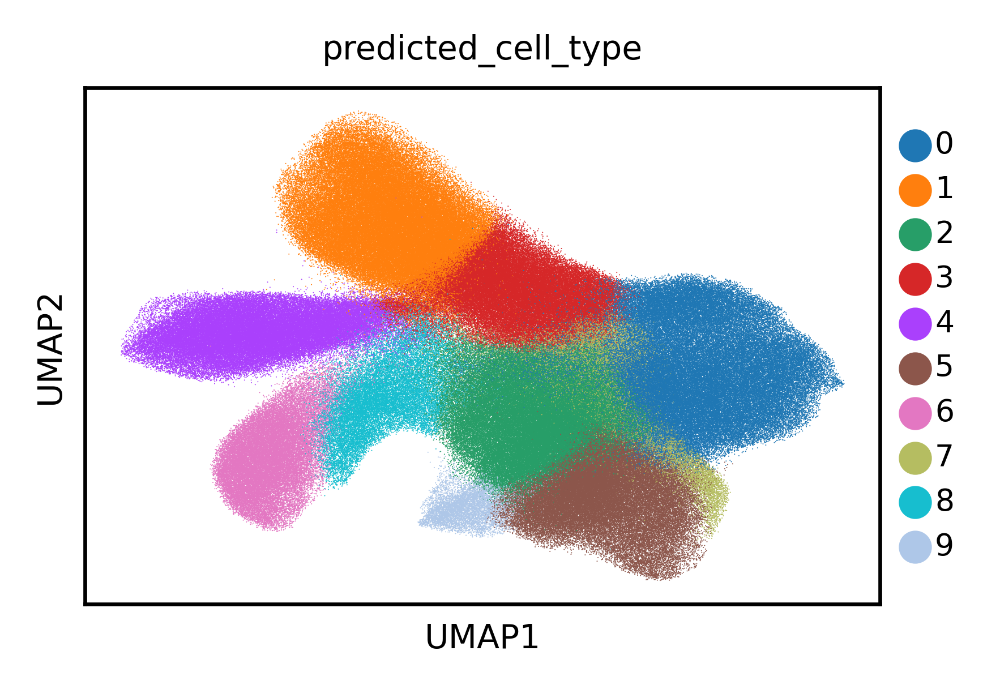

In [349]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_cell_cluster_key)

In [350]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [351]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

['3', '4', '0', '2', '7', '8', '6', '1', '5', '9']
predicted_cell_type
0    91798
1    88812
2    75168
3    62571
4    60003
5    59712
6    34212
7    31629
8    22579
9     7477
Name: count, dtype: int64
Optimal Mappings:
B-cell -> 4 (Overlap: 0)
NK/T cell -> 5 (Overlap: 17275)
endothelial -> 3 (Overlap: 1164)
epithelial -> 8 (Overlap: 8842)
fibroblast -> 0 (Overlap: 53802)
mast -> 6 (Overlap: 14)
myeloid -> 7 (Overlap: 16394)
neutrophil -> 2 (Overlap: 32808)
plasmablast -> 9 (Overlap: 7158)
tumor -> 1 (Overlap: 87587)

Total Maximum Overlap: 225044


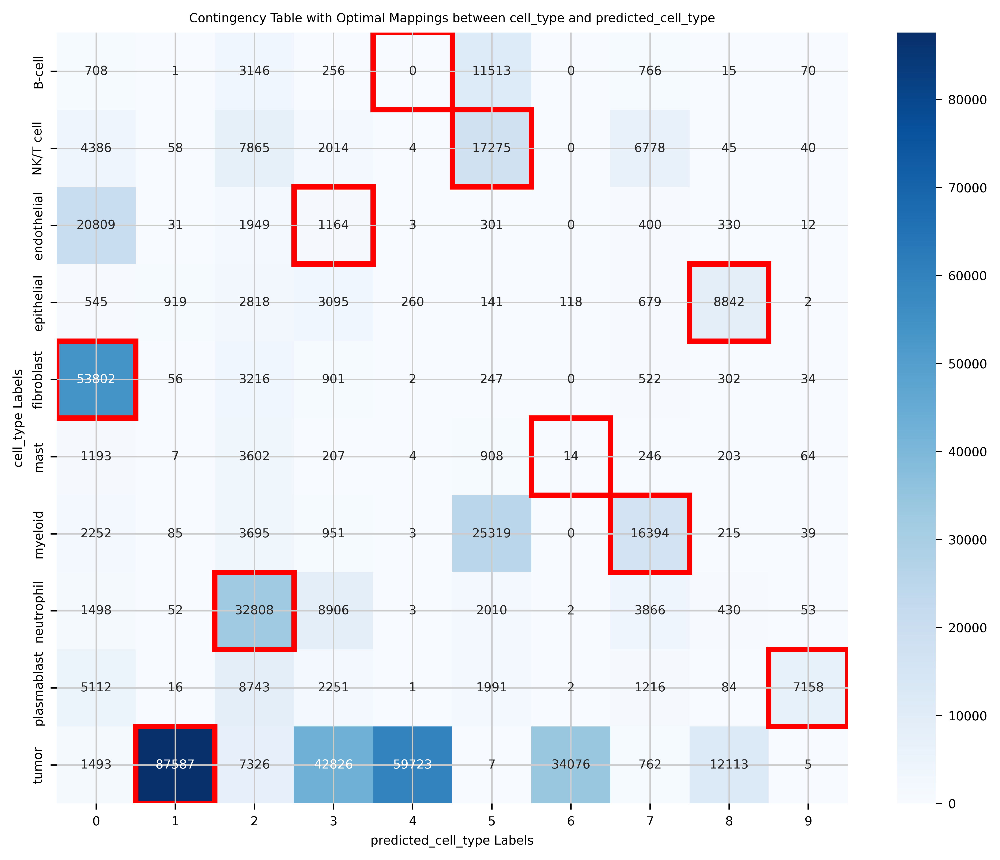

In [352]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [353]:
inferred_cell_types_ordered = [
    '4',
    '5',
    '3',
    '8',
    '0',
    '6',
    '7',
    '2',
    '9',
    '1']

/tmp/ipykernel_2331359/2292754212.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


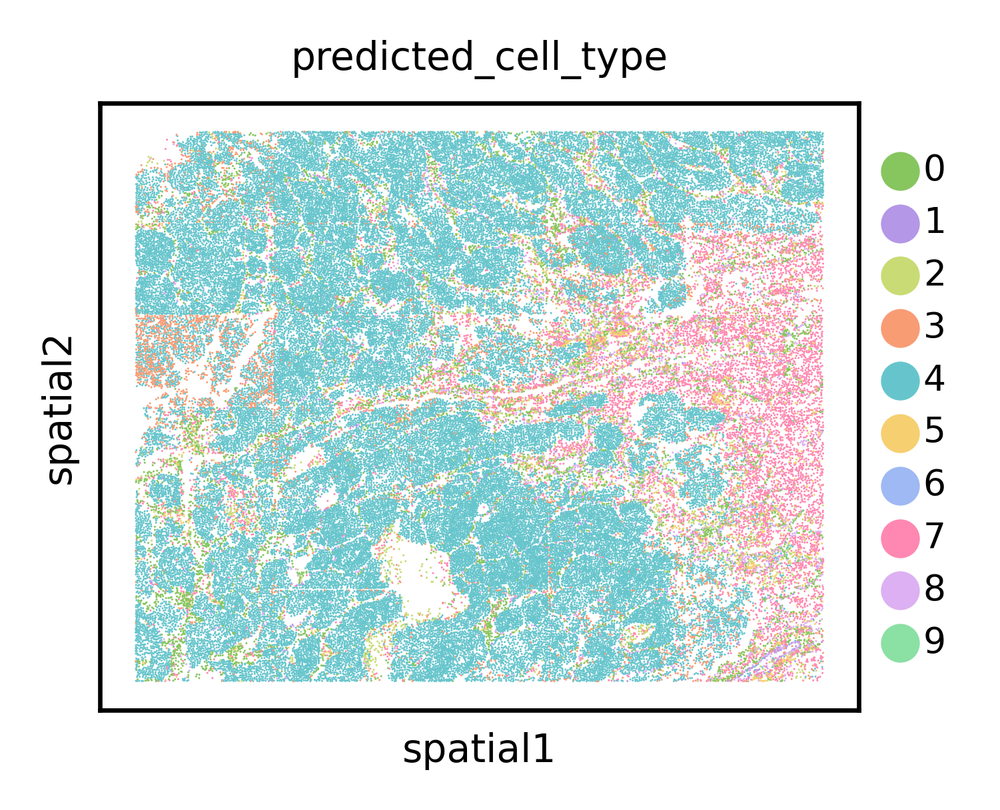

/tmp/ipykernel_2331359/2292754212.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


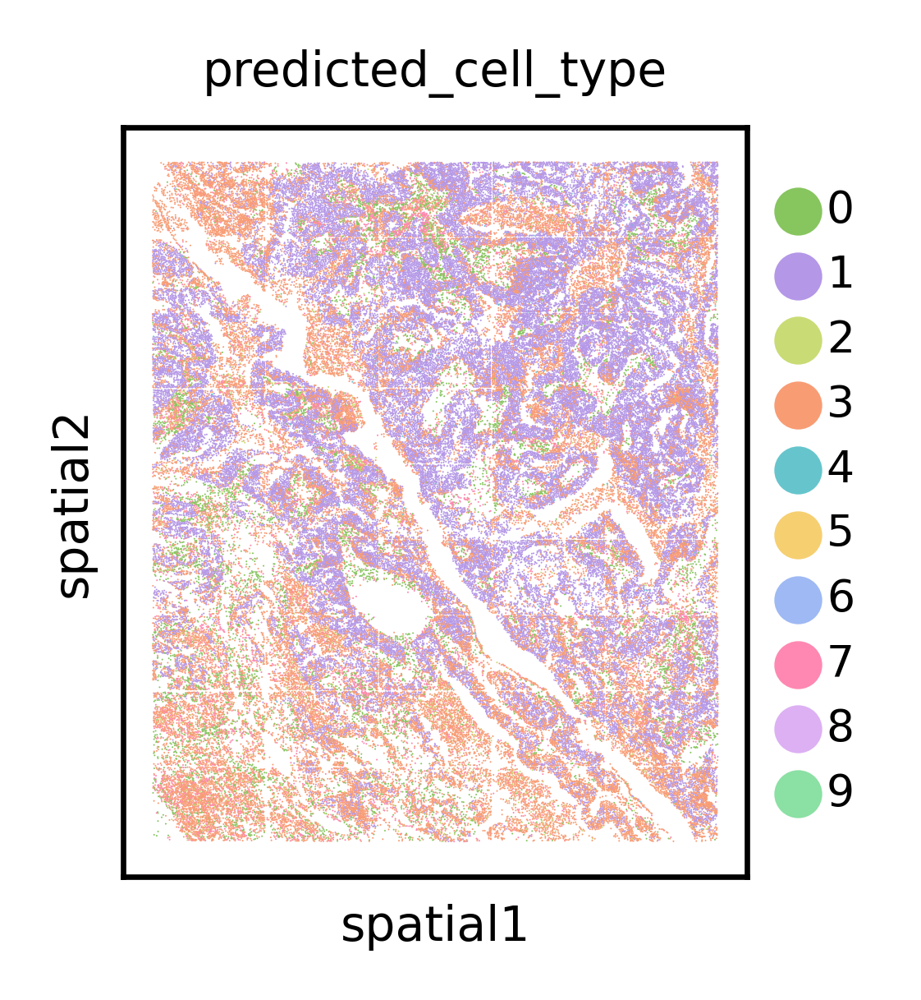

/tmp/ipykernel_2331359/2292754212.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


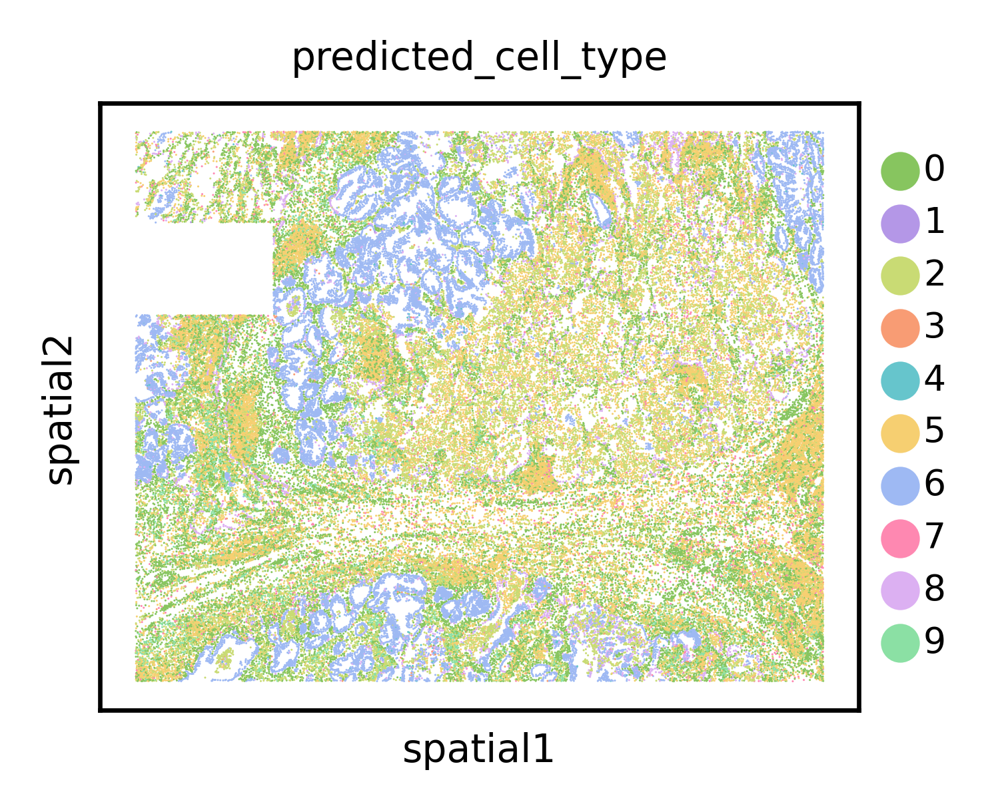

/tmp/ipykernel_2331359/2292754212.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


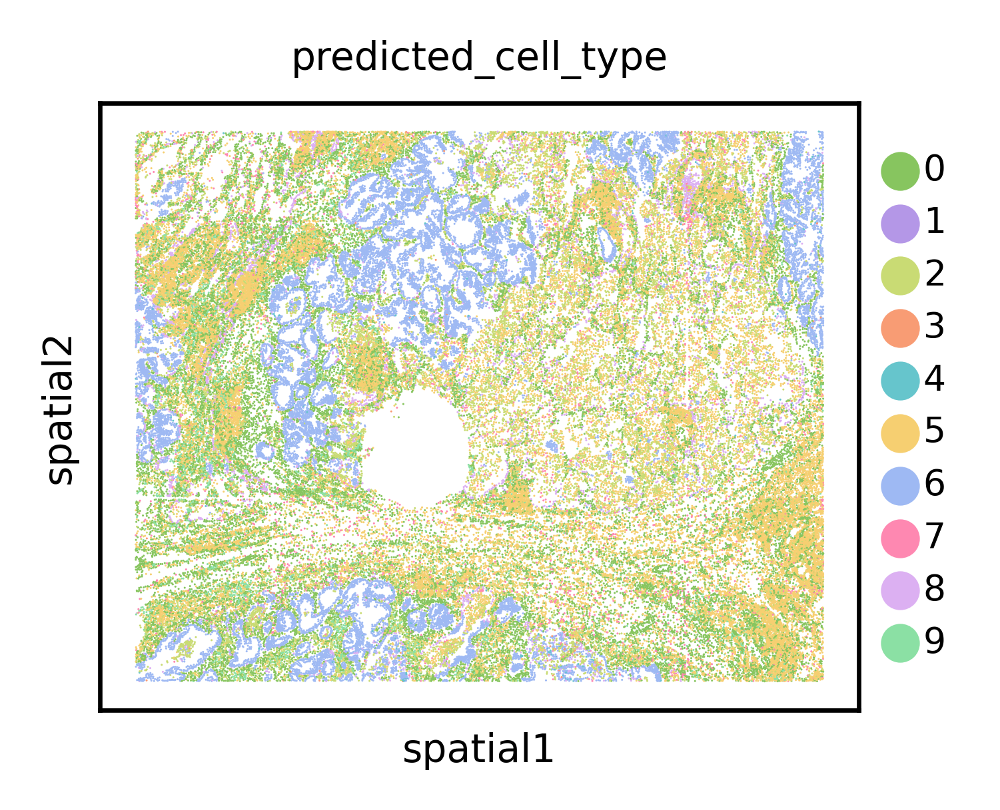

/tmp/ipykernel_2331359/2292754212.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


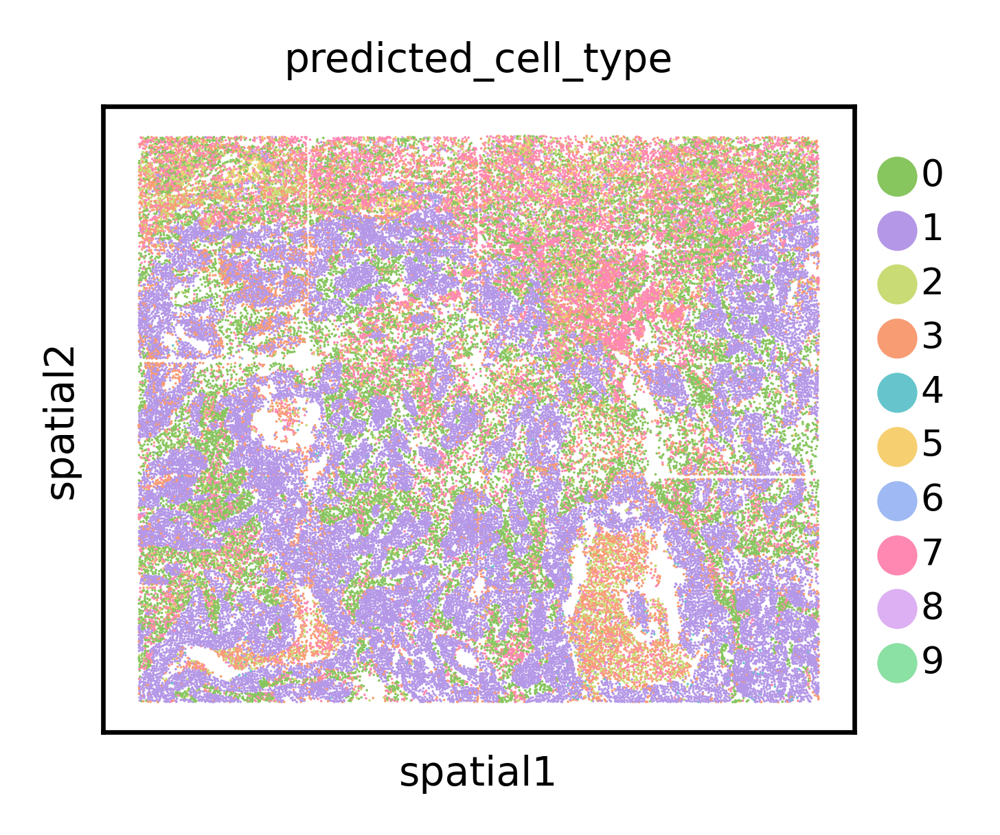

/tmp/ipykernel_2331359/2292754212.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


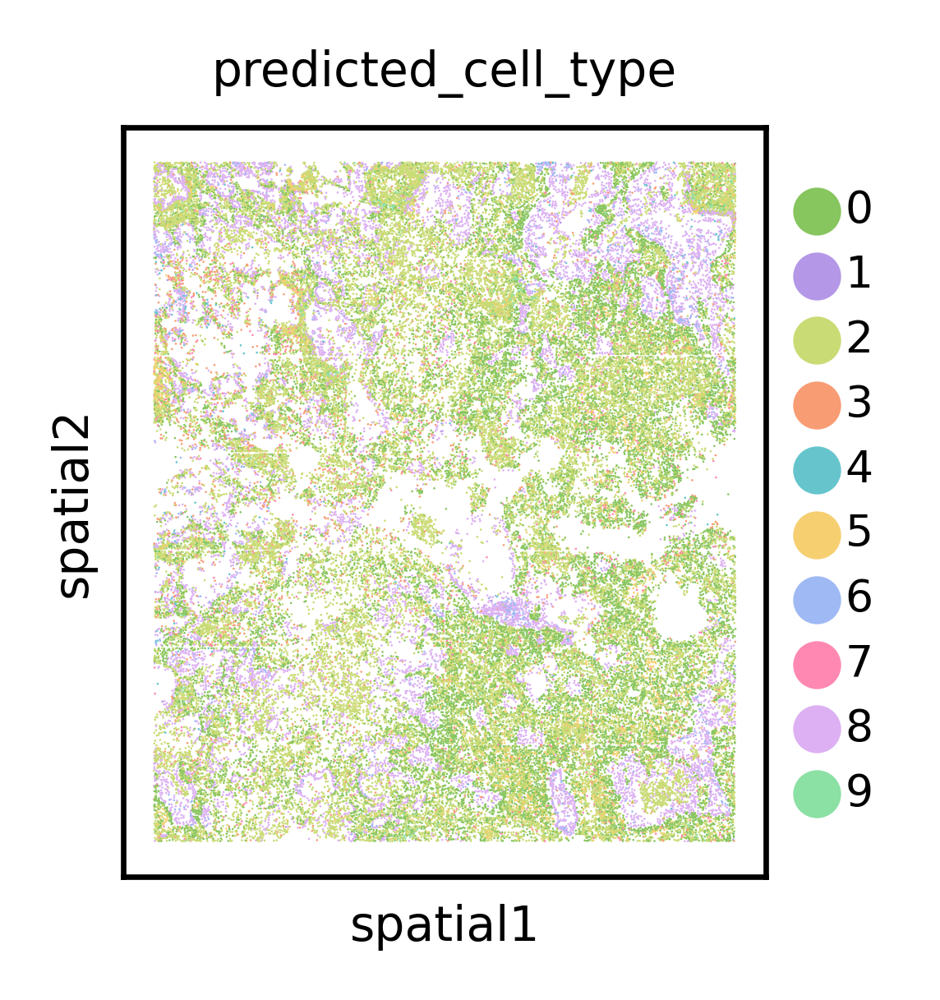

In [354]:
# Plot TERRA cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [355]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.4373778144938701.
ARI scores: 0.2596297959450561.


#### 3.2.4 Quantitative Performance

In [356]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.4373778144938701, 0.43226270345313267, 0.4325343448003438, 0.43380442070380426, 0.4332780907434166, 0.4382689703555274, 0.42621553614280067, 0.42986412054391315, 0.4265019749846238].
ARI scores: [0.2596297959450561, 0.2657307404215029, 0.2657126560448735, 0.266685057788436, 0.2659356431483253, 0.2603609699239167, 0.2519765830667164, 0.25107564219254114, 0.25239210972578535].


### 3.3 xhk1007-CV1-41b_1p (Xenium Human Renal Cell Carcinoma)

#### 3.3.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'xhk1007-CV1-41b_1p'
batches = ['CV1-KID-0-FT-3', # 'batch1',
           'CV1-KID-0-FT-1' # 'batch14'
          ]
cell_type_key = 'level_2_cell_type'
sample_key = 'batch'
batch_key = 'batch_new'
spot_sizes = [30] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
print(adata.obs[cell_type_key].value_counts())

#### 3.3.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')

#### 3.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 9)
latent_leiden_resolution = 0.3

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '2',
    '1',
    '8',
    '4',
    '5',
    '6',
    '3',
    '9',
    '7',
    '0']

In [ ]:
# Plot TERRA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.4 shp75-4b_1p (STARmap Human Placenta)

#### 3.4.1 Load Data

In [388]:
# Define dataset params
dataset_name = 'shp75-4b_1p'
batches = ['STARmap-ISS_sample_W11_',
           'STARmap-ISS_sample_W7_',
           'STARmap-ISS_sample_W8-2_',
           'STARmap-ISS_sample_W9_',
          ]
cell_type_key = 'leiden'
sample_key = 'sample'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

In [389]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/team361/sb75/ENVS/rapids-singlecell-ter

In [390]:
print(adata.obs[cell_type_key].value_counts())

leiden
0     1953
1     1926
2     1792
3     1682
4     1576
5     1418
6     1363
7     1228
8     1086
9      904
10     443
11     431
12     377
Name: count, dtype: int64


#### 3.4.2 Retrieve Embeddings

In [320]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

/nfs/team361/sb75/terra/src/app/inference/harmonize.py:124: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names
2026-06-04 19:35:52 | [INFO] Loading token dictionary from /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/token_dictionary.pkl.


Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 0 genes.
Before cell filtering: 16179 cells.
After cell filtering: 16179 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 946 genes.
After gene filtering: 946 genes (removed 0 genes).
Start processing sample: W11...
Harmonizing sample W11...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw count

/nfs/team361/sb75/terra/src/terra/tokenizers/cell_tokenizers.py:678: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Retrieving tokens for neighborhood cells.


2026-06-04 19:35:53 | [INFO] Creating Hugging Face dataset...
2026-06-04 19:35:53 | [INFO] Using generator for dataset creation.
2026-06-04 19:35:54 | [INFO] Formatting gene tokens...
Map (num_proc=4):   0%|                                           | 0/2498 [00:00<?, ? examples/s]Exception ignored in: <_io.BytesIO object at 0x14c2271f6d90>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x14c2271f5530>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Map (num_proc=4): 100%|███████████████████████████████| 2498/2498 [00:05<00:00, 482.

Tokenized sample W11.
Start processing sample: W8-2...
Harmonizing sample W8-2...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 0 genes.
Before cell filtering: 4487 cells.
After cell filtering: 4487 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.
Before gene filtering: 946 genes.
After gene filtering: 946 genes (removed 0 genes).
Harmonized sample W8-2.
Tokenizing sample W8-2...
STEP 1: LOADING CO

... (8 outputs left out)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
2026-06-04 19:36:30 | [INFO] Dataloader and -sampler created.
2026-06-04 19:36:30 | [INFO] Loaded pretrained target encoder from epoch 8 with msg: <All keys matched successfully>.
2026-06-04 19:36:30 | [INFO] Finished loading checkpoint with read path: /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/terra/src/app/inference/embed.py:257: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
127it [02:31,  1.19s/it]

Embedded tokenized data.


In [321]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

... storing 'batch' as categorical


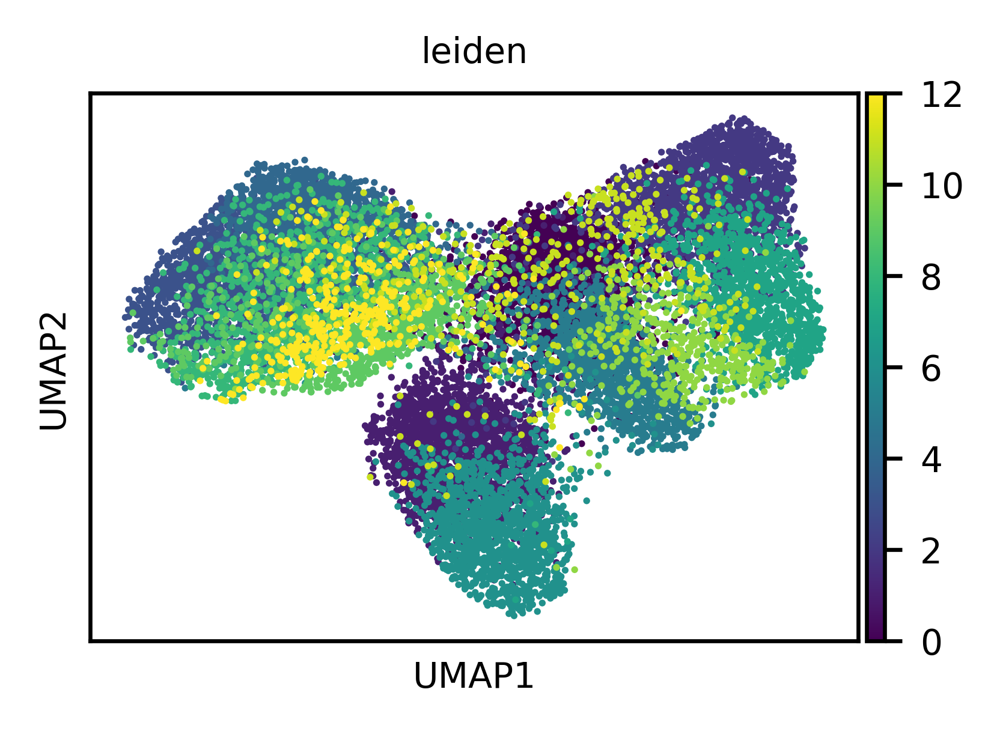

In [322]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [323]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [409]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.4.3 Highlight Run (Matching Ground Truth Number of Niches)

In [410]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 13)
latent_leiden_resolution = 1.62

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [411]:
adata.obs[latent_cell_cluster_key].value_counts()

predicted_cell_type
0     1817
1     1731
2     1700
3     1628
4     1506
5     1488
6     1371
7     1338
8     1065
9      978
10     573
11     495
12     470
13      19
Name: count, dtype: int64

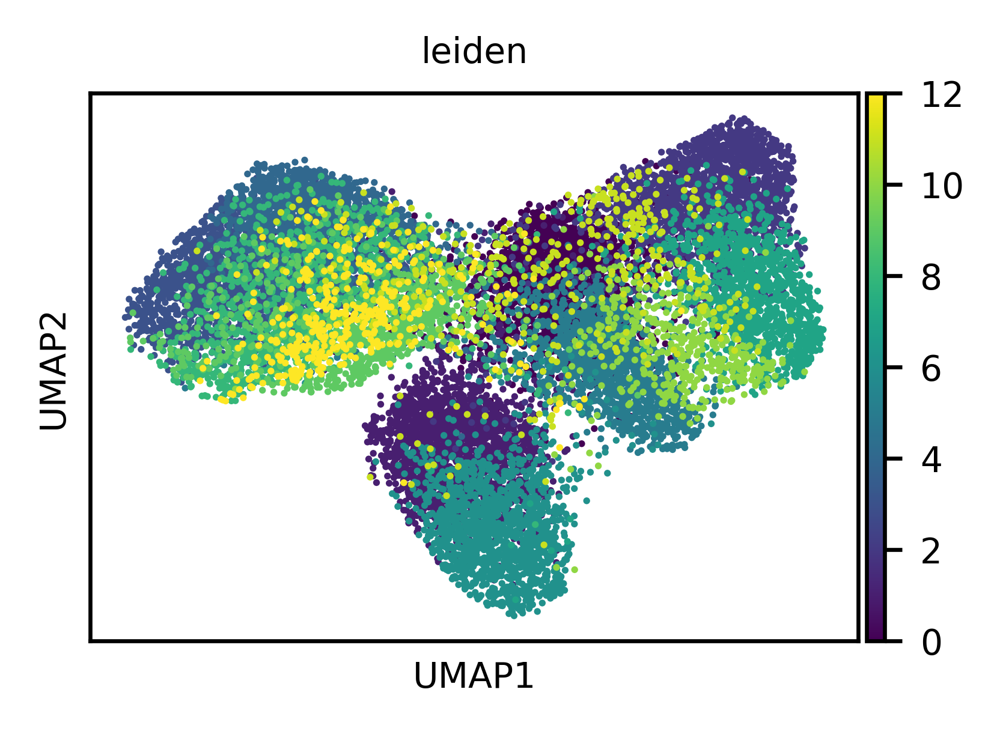

In [412]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [413]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [414]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

['12', '3', '0', '10', '1', '4', '6', '9', '8', '11', '7', '2', '5', '13']
predicted_cell_type
0     1817
1     1731
2     1700
3     1628
4     1506
5     1488
6     1371
7     1338
8     1065
9      978
10     573
11     495
12     470
13      19
Name: count, dtype: int64
Optimal Mappings:
0 -> 0 (Overlap: 1379)
1 -> 1 (Overlap: 1477)
2 -> 4 (Overlap: 1192)
3 -> 6 (Overlap: 908)
4 -> 3 (Overlap: 1091)
5 -> 2 (Overlap: 1163)
6 -> 5 (Overlap: 1139)
7 -> 7 (Overlap: 889)
8 -> 8 (Overlap: 421)
9 -> 9 (Overlap: 609)
10 -> 11 (Overlap: 3)
11 -> 10 (Overlap: 127)
12 -> 12 (Overlap: 8)

Total Maximum Overlap: 10406


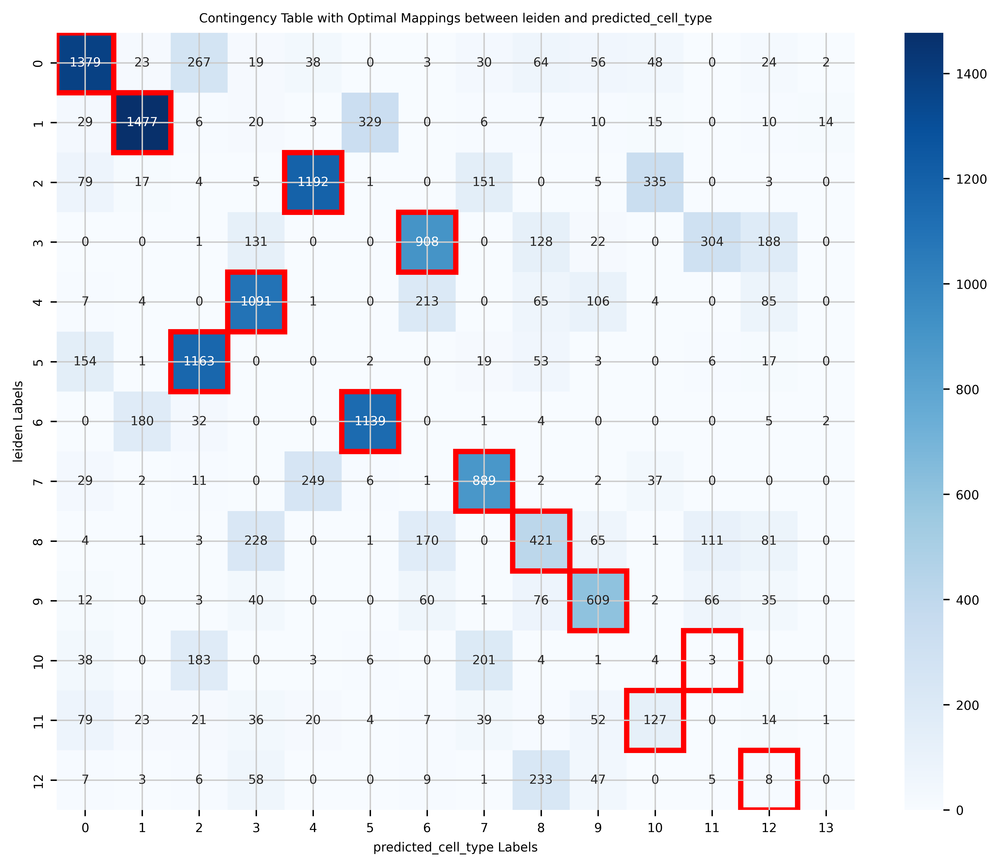

In [415]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [416]:
inferred_cell_types_ordered = [
    '0',
    '1',
    '4',
    '6',
    '3',
    '2',
    '5',
    '7',
    '8',
    '9',
    '11',
    '10',
    '12',]

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


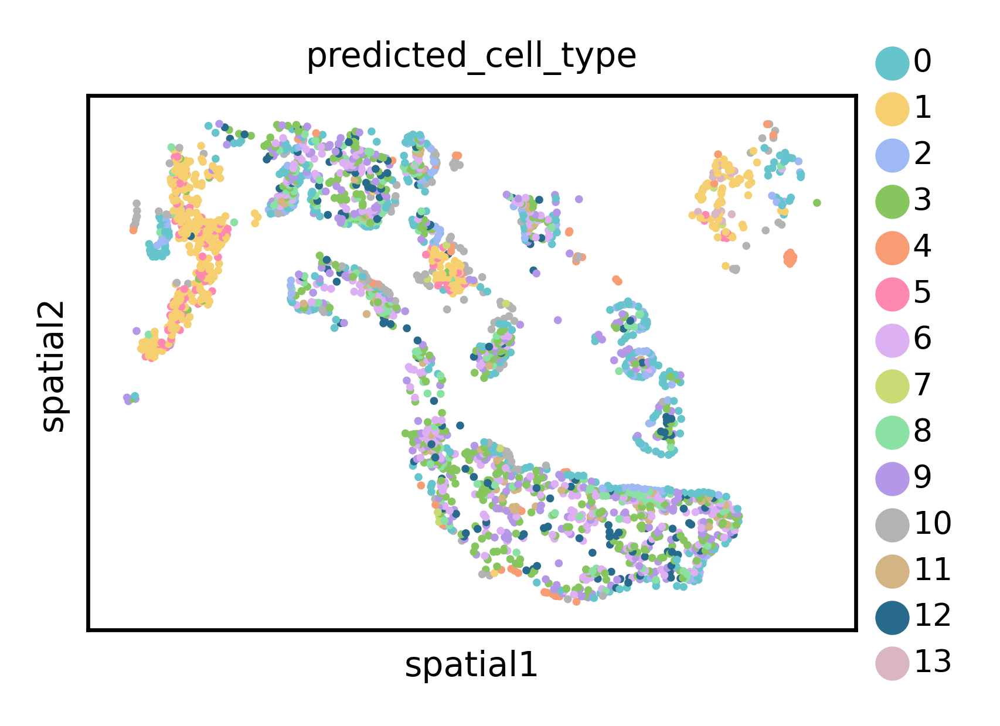

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


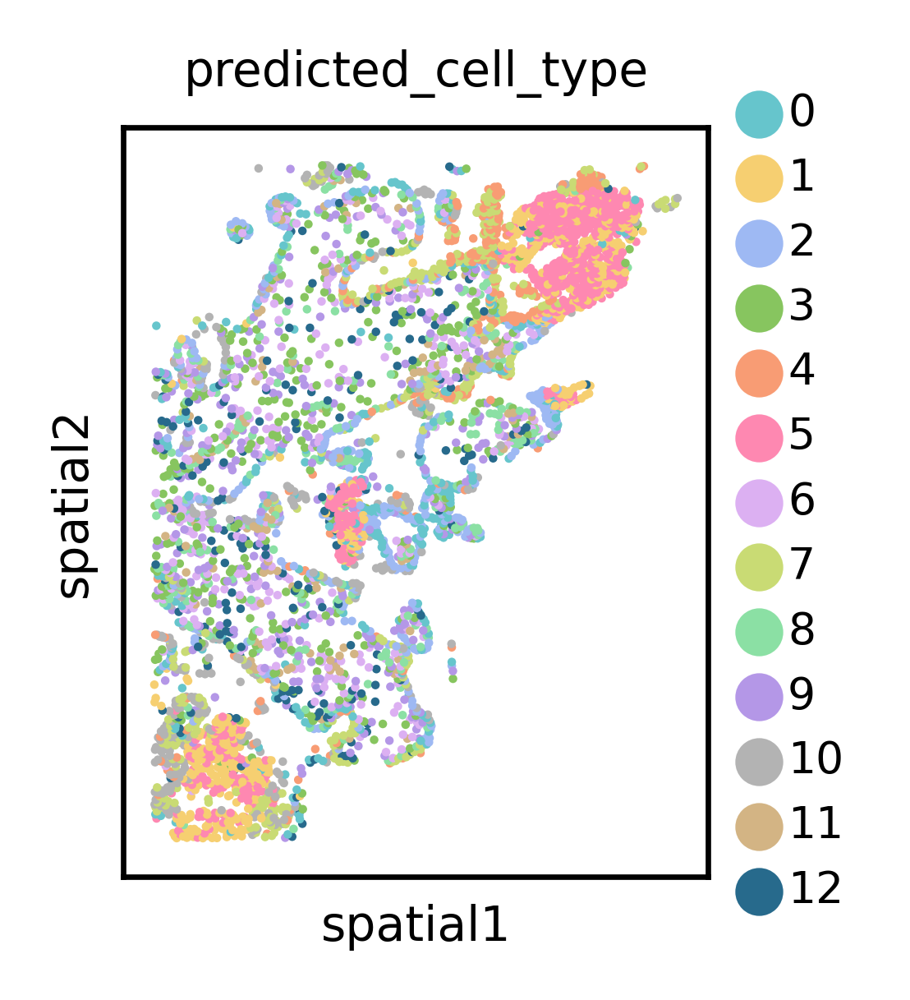

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


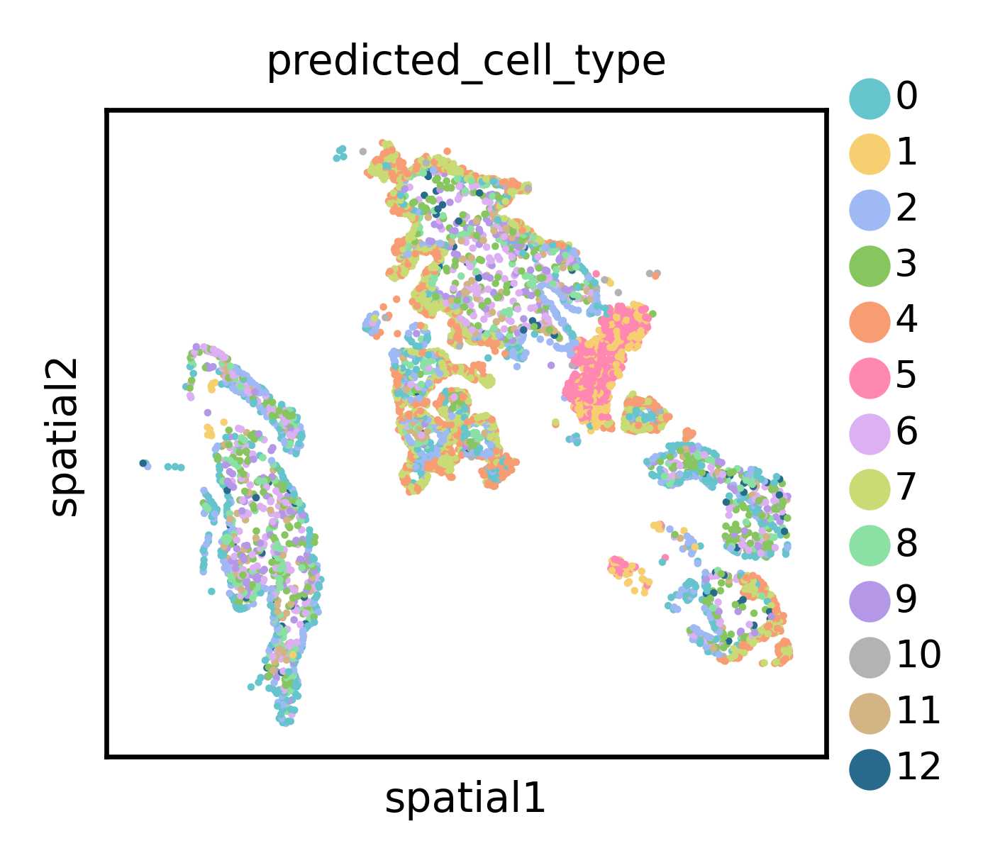

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


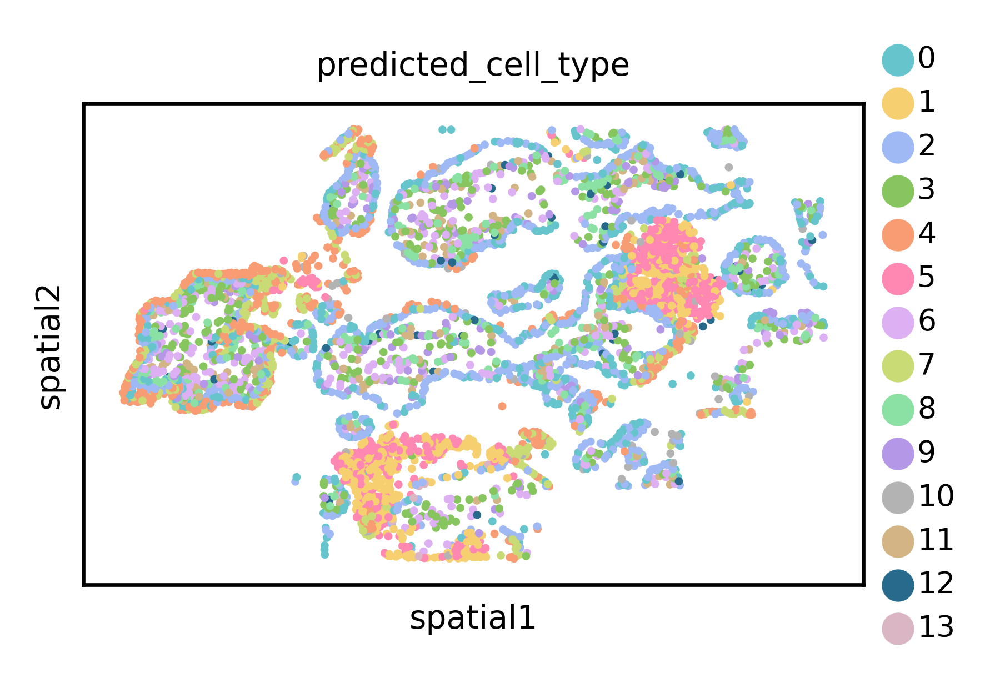

In [417]:
# Plot TERRA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [418]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5799758750517457.
ARI scores: 0.4871535706506378.


#### 3.4.4 Quantitative Performance

In [419]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.5799758750517457, 0.5809012442158009, 0.5795459717307616, 0.5837501508853569, 0.572858474087595, 0.5780938817122491, 0.5726162748450527, 0.5742072395694973, 0.5772617843654492].
ARI scores: [0.4871535706506378, 0.49308716481345066, 0.487924809902039, 0.4860267216010986, 0.4601977973679764, 0.48223034916696667, 0.46980923960695337, 0.4737269902848858, 0.48177762718916917].


### 3.5 xhp1016-18b_1p (Xenium Human Pancreas)

#### 3.5.1 Load Data

In [357]:
# Define dataset params
dataset_name = 'xhp1016-18b_1p'
batches = ['output-XETG00055__0073068__Hml4-PNC-0-FFPE-1-s4__20250814__132610', # batch3
           'output-XETG00055__0073075__Hml7-PNC-0-FFPE-1-s4__20250814__132610', # batch12
          ]
cell_type_key = 'Annotation_high'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

In [358]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/tmp/ipykernel_2331359/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/anndata/_core/anndata.py:1796: UserWarning: Observation names are not uniq

In [359]:
print(adata.obs[cell_type_key].value_counts())

Annotation_high
Stromal (Fibroblast)         64627
Exocrine (Ductal)            23995
Endothelial                  23875
Exocrine (Acinar)            21260
Tip                          21213
Stromal (mural)              14609
Endocrine                    10385
Neural crest                 10296
Immune (Macrophage)           3750
Immune (T/NK/ILC)             2513
Immune (B)                    1773
Endocrine progenitor          1584
Erythrocyte/Megakaryocyte     1422
Stromal (Mesothelium)         1197
Immune (Granulocyte)           544
Immune (Mast cell)             166
Immune (Dendritic cell)         60
Epithelial Progenitor           47
Name: count, dtype: int64


In [360]:
adata.uns[batch_key] = adata.obs[batch_key].values.tolist()[0]

#### 3.5.2 Retrieve Embeddings

In [328]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=None,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

No `sample_key` specified. Start processing entire AnnData. This is the intended behavior if the AnnData object contains only one sample. Otherwise please specify a `sample_key` or results will be invalid!!!
Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 5047.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 25.
Genes excluded due to not enough pretraining occurrences: {'ENSG00000204983', 'ENSG00000137343', 'ENSG00000169733', 'ENSG00000091704', 'ENSG00000188931', 'ENSG00000036565', 'ENSG00000204347', 'ENSG00000010310',

2026-06-04 19:39:19 | [INFO] Loading token dictionary from /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/token_dictionary.pkl.


Before gene filtering: 5022 genes.
After gene filtering: 5022 genes (removed 0 genes).
Harmonized AnnData.
Tokenizing AnnData.
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/terra/src/terra/tokenizers/cell_tokenizers.py:678: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts (sparse version).
Retrieving tokens for neighborhood cells.


2026-06-04 19:41:57 | [INFO] Creating Hugging Face dataset...
2026-06-04 19:41:57 | [INFO] Using generator for dataset creation.
2026-06-04 19:42:47 | [INFO] Formatting gene tokens...
Map (num_proc=4):   0%|                                         | 0/203316 [00:00<?, ? examples/s]Exception ignored in: <_io.BytesIO object at 0x14c237a51bc0>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x14c237a518f0>
Traceback (most recent call last):
  File "/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/pickle.py", line 1008, in _batch_setitems
    tmp = list(islice(it, self._BATCHSIZE))
BufferError: Existing exports of data: object cannot be re-sized
Exception ignored in: <_io.BytesIO object at 0x14c237a518f0>
Traceback (most recent 

... (3 outputs left out)

/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
2026-06-04 19:49:20 | [INFO] Dataloader and -sampler created.
2026-06-04 19:49:20 | [INFO] Loaded pretrained target encoder from epoch 8 with msg: <All keys matched successfully>.
2026-06-04 19:49:20 | [INFO] Finished loading checkpoint with read path: /nfs/team361/sb75/terra-reproducibility/artifacts/models/10112025_185828_463/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/terra/src/app/inference/embed.py:257: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
1589it [31:49,  1.20s/it]


Embedded tokenized data.


In [329]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

... storing 'batch' as categorical


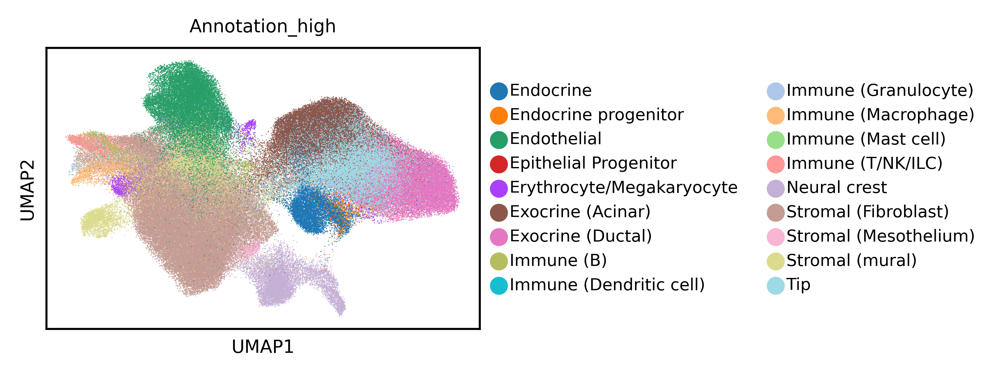

In [330]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [331]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [377]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.5.3 Highlight Run (Matching Ground Truth Number of Niches)

In [378]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 16)
latent_leiden_resolution = 0.81

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [379]:
adata.obs[latent_cell_cluster_key].value_counts()

predicted_cell_type
0     32929
1     22917
2     21431
3     21398
4     19854
5     18299
6     17852
7      9760
8      9666
9      9032
10     8417
11     4305
12     3427
13     2635
14      903
15      491
Name: count, dtype: int64

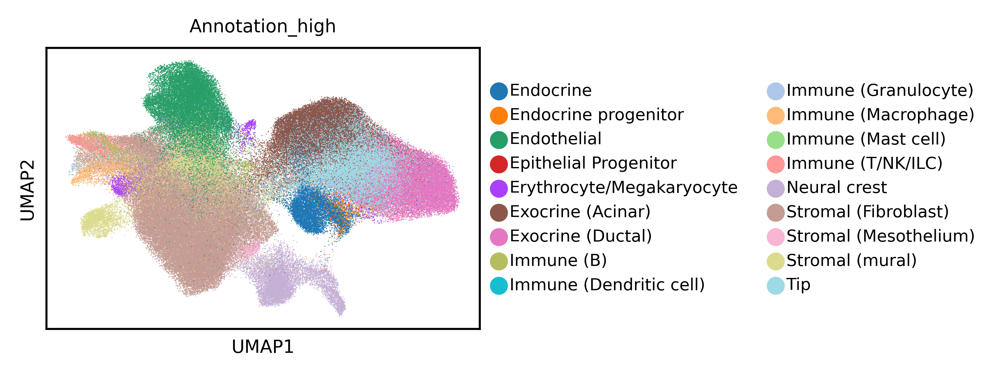

In [380]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [381]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [382]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

['9', '10', '12', '13', '5', '0', '3', '1', '6', '2', '4', '7', '8', '15', '11', '14']
predicted_cell_type
0     32929
1     22917
2     21431
3     21398
4     19854
5     18299
6     17852
7      9760
8      9666
9      9032
10     8417
11     4305
12     3427
13     2635
14      903
15      491
Name: count, dtype: int64
Optimal Mappings:
Endocrine -> 8 (Overlap: 8217)
Endocrine progenitor -> 7 (Overlap: 152)
Endothelial -> 3 (Overlap: 19430)
Erythrocyte/Megakaryocyte -> 1 (Overlap: 782)
Exocrine (Acinar) -> 4 (Overlap: 14496)
Exocrine (Ductal) -> 2 (Overlap: 18213)
Immune (B) -> 12 (Overlap: 87)
Immune (Dendritic cell) -> 13 (Overlap: 0)
Immune (Granulocyte) -> 15 (Overlap: 1)
Immune (Macrophage) -> 10 (Overlap: 2403)
Immune (T/NK/ILC) -> 11 (Overlap: 148)
Neural crest -> 9 (Overlap: 8688)
Stromal (Fibroblast) -> 0 (Overlap: 30396)
Stromal (Mesothelium) -> 14 (Overlap: 856)
Stromal (mural) -> 5 (Overlap: 6509)
Tip -> 6 (Overlap: 11162)

Total Maximum Overlap: 121540


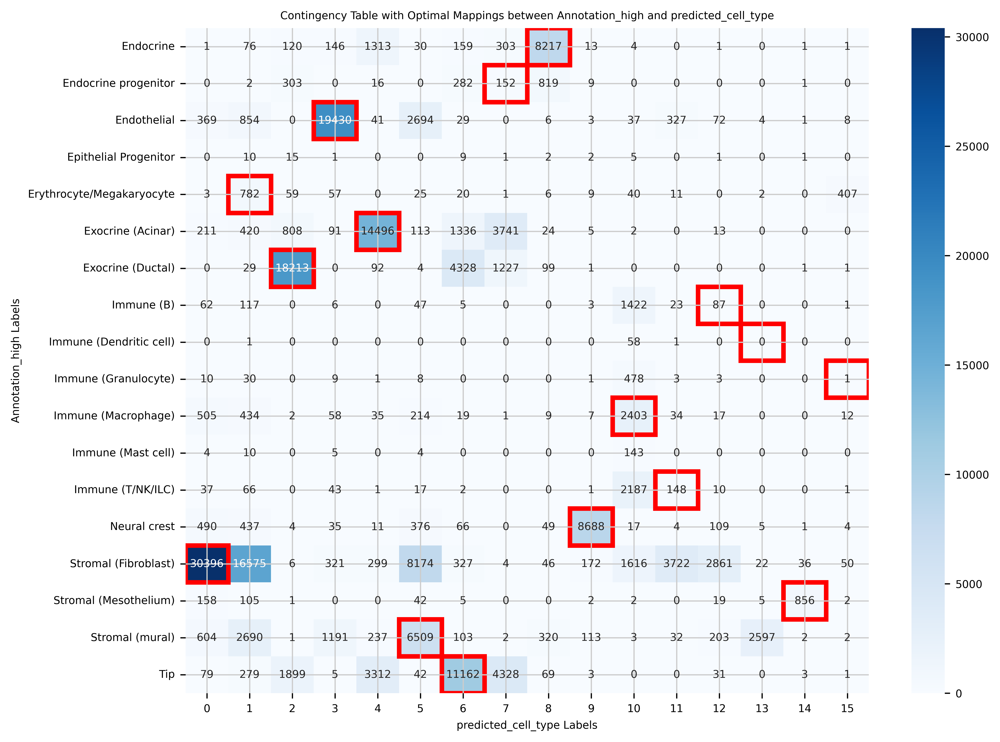

In [383]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [384]:
inferred_cell_types_ordered = [
    '8',
    '7',
    '3',
    '1',
    '4',
    '2',
    '12',
    '13',
    '15',
    '10',
    '11',
    '9',
    '0',
    '14',
    '5',
    '6']

/tmp/ipykernel_2331359/4022236810.py:21: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-terra/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


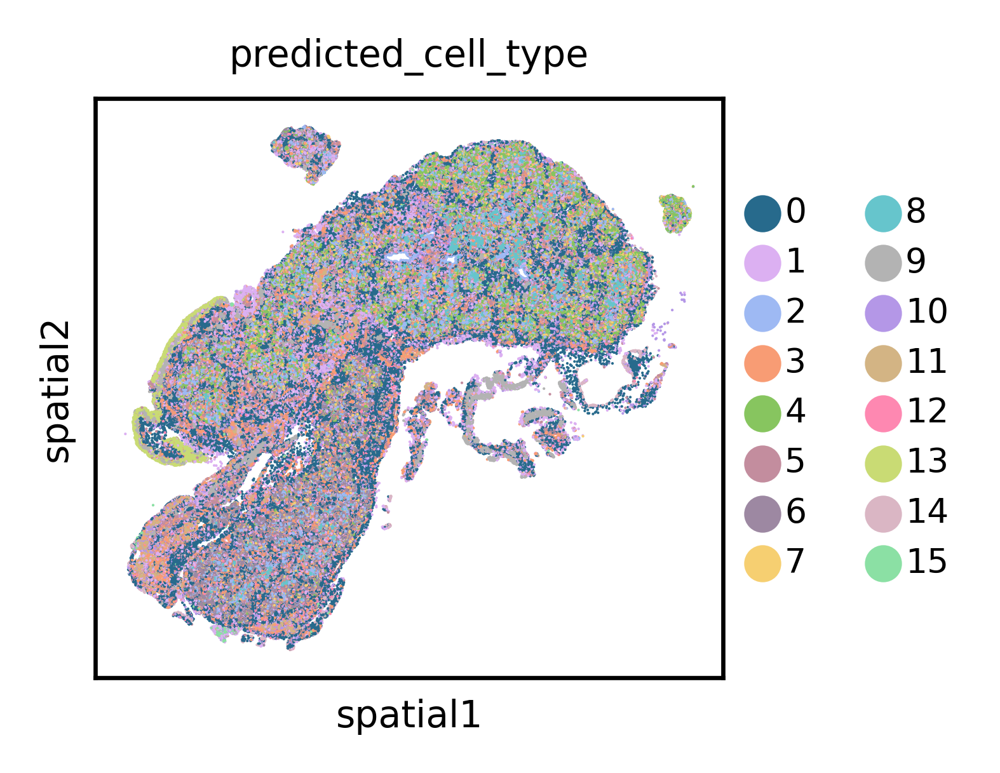

In [385]:
# Plot TERRA cell type
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_terra_cell_types_{model_timestamp}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [386]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5815070014456344.
ARI scores: 0.42608448853833714.


#### 3.5.4 Quantitative Performance

In [387]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='cell',
                 key_added=latent_cell_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out


NMI scores: [0.5815070014456344, 0.5882735011578509, 0.5793092274983384, 0.5794334310175084, 0.5733534531526776, 0.5780846193796213, 0.5789530990677144, 0.5787026292170523, 0.5652918986419873].
ARI scores: [0.42608448853833714, 0.4317413357876507, 0.42385422114230914, 0.4238610621942664, 0.3931665301741099, 0.4206973577047837, 0.4161332504273526, 0.4196751788902474, 0.3767775841902392].


### 3.6 shk2005-1b_1p (SlideSeqV2 Human Kidney)

#### 3.6.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'shk2005-1b_1p'
cell_type_key = 'cell_type'
spot_size = 30

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Puck_200104_15_with_emb_NEMO_commongenes.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs[cell_type_key].isna()]

In [ ]:
adata.obs[cell_type_key].value_counts()

#### 3.6.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=None,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_cell_type_{model_timestamp}.h5ad')

#### 3.6.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 0.85

sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=latent_cell_cluster_key)

In [ ]:
# Save updated AnnData
try:
    del(adata.uns['spatial'])
except:
    pass
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
# Read AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_clustered_cell_type_{model_timestamp}.h5ad')

In [ ]:
print(adata.obs[latent_cell_cluster_key].unique().tolist())
print(adata.obs[latent_cell_cluster_key].value_counts())
max_overlap_plot(adata.obs, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '0',
    '11',
    '10',
    '4',
    '2',
    '6',
    '1',
    '7',
    '8',
    '9',
    '5',
    '3',]

In [ ]:
# Plot TERRA cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_terra_cell_types_{model_timestamp}.svg'
sc.pl.spatial(adata,
              color=latent_cell_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Plot TERRA cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_terra_cell_types_{model_timestamp}.svg'
sc.pl.spatial(adata,
              color=latent_cell_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.6.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                  neighbors_key='cell',
                  key_added=latent_cell_cluster_key,
                  resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_cell_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_terra_metric_scores_cell_type_{model_timestamp}.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.7 xhb1002-75b_3p (Xenium Human Brain GBM)

#### 3.3.1 Load Data

In [ ]:
# Define dataset config
dataset_name = 'xhb1002-AT9-6b_1p'
batches = ['AT9-BRA-4-FO-2-S38',
           'AT9-BRA-4-FO-4-S45-I ']
obsm_key = 'cell_emb_layer_12'
cell_type_key = 'leiden_log1pnorm_res-1'
sample_key = 'batch'
batch_key = 'batch'

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        print(file)
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
print(adata.obs[cell_type_key].value_counts())

#### 3.3.2 Retrieve Embeddings

In [ ]:
# Generate zero-shot embeddings for cells
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    min_cells_per_gene=min_cells_per_gene,
    batch_size=128)

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/TERRA/{dataset_name}_embedded_{model_timestamp}.h5ad')